# Integrative Assignment on Week 04 Material — Pelican Row Growers
## Find the hidden relationship

**ISM4543 | Applied Data Science | Fall 2026**

| | |
|---|---|
| **Due** | Monday, September 21, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Three deliverables: this notebook (`.ipynb`), your **AI Usage Report** (the full Gemini conversation export *plus* your written account of it), and a **3–5 minute video walkthrough** (hard stop at five minutes). Submit the video as a **file upload on the Canvas assignment** or a **publicly accessible link in the Canvas submission comment** — never embedded in this notebook. **No video, or a link we cannot open, is −15 points.** The reflection section below is part of the notebook. |
| **AI policy** | AI assistance is **expected**, and documenting it is **required**. Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Grade questions** | Raise any grading issue within **5 days** of the evaluation being posted. After that the evaluation stands. |

---

> **How the points are shown.** The points still belong to the six components above, and every
> prompt below shows its share of them, for example **(4 pts — Problem Framing)**. Across the
> notebook the shares add up to each component's total.

## The client: Pelican Row Growers

**Pelican Row Growers** runs an indoor vertical farm in Tampa. It grows microgreens in trays on
50-metre grow racks, sells them to restaurants and grocers for about **\$0.07 per gram**, and
harvests about **1,500 trays a week**.

Last season the farm ran a growing trial on **500 trays**. The team deliberately varied three
things: the nutrient dose, the grow-room temperature (anywhere from 16 to 31 °C) and the amount
of seed sown. It logged everything else it could about each tray.

- **Imani Brooks, Chief Operating Officer:** *"I set three dials: temperature, nutrient and
  seed. Next season our planning system sets them from an equation, not from a black box, and I
  have to defend that equation to our investors. I want the equation, and I want to see how you
  found it."*
- **Wes Kowalski, Head Grower:** *"Warm rooms grow faster. We run at 26 °C, and I'm not
  changing that without proof. And never sow from old seed lots: they don't do as well."*
- **Alicia Moreno, Facilities Manager:** *"A sensor vendor ran a regression on the trial data,
  and humidity costs us yield. I've asked for \$38,000 of dehumidifiers."*

Imani adds: *"Our nutrient concentrate costs \$0.04 per mL. Purchasing wants to dose every tray
at the full 100 mL."*

### About this data

The trial is **simulated**, so there is a right answer to find; the farm, the people and the
decisions are the setting. Harvest weight was generated from a **hidden rule** plus random
tray-to-tray variation:

- The rule is a **sum of pieces**. Each piece is a number times a shape of **one** column; no
  piece multiplies two columns together.
- Each shape is one of this week's families: a **straight line**, a **polynomial** (x², x³, …),
  a **logarithm**, or a **sine/cosine wave**.
- Some columns may play no part at all.
- Trays grown side by side under identical settings still differ. The **typical tray-to-tray
  variation is about 12 g**, and no model can predict it.

### Your job

Recover the rule (which columns matter, in what shape, with what numbers) using the process from
this week's hidden-relationship demonstrations. Show the evidence for every piece, then answer
Imani's questions with it.

### How to work (the demonstrations' process)

1. Split first.
2. After **every** change, plot the training residuals against **every** input and write one
   sentence about what you see.
3. Keep one growing table of training RMSE, test RMSE and test R².
4. Compare a **few** candidates per change on test RMSE.
5. Stop only when no residual plot shows a pattern **and** test RMSE is near the tray-to-tray
   variation.

### Data dictionary

File `pelican_row_trays.csv`: 500 rows × 8 columns, no missing values. It loads by URL in the
setup cell.

| Column | Meaning |
|---|---|
| `tray_id` | Tray identifier (`PR-0001` …); an identifier, not a feature |
| `nutrient_ml` | Millilitres of nutrient concentrate added over the grow cycle |
| `room_temp_c` | Average grow-room air temperature over the cycle, °C |
| `rel_humidity_pct` | Average relative humidity of the grow room, % |
| `rack_position_m` | Distance of the tray's slot from the front end of its 50 m rack, metres |
| `seed_g` | Grams of seed sown on the tray |
| `seed_lot_age_days` | Days from the seed lot's packing date to sowing |
| `harvest_g` | Harvested weight of the tray, grams (**the target**) |

---

## Part 0: Setup (given)

Run these cells first. You do not need to change them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')   # light gridlines at every tick
pd.set_option('display.width', 160)

DATA_URL = "https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week04/assignment/pelican_row_trays.csv"
df = pd.read_csv(DATA_URL)

inputs = ['nutrient_ml', 'room_temp_c', 'rel_humidity_pct', 'rack_position_m', 'seed_g', 'seed_lot_age_days']
print(f"{len(df)} trays x {df.shape[1]} columns")
df.head()

500 trays x 8 columns


,tray_id,nutrient_ml,room_temp_c,rel_humidity_pct,rack_position_m,seed_g,seed_lot_age_days,harvest_g
0,PR-0001,42.1,23.6,59,15.3,32.5,34,380.2
1,PR-0002,5.4,17.3,89,7.6,18.2,25,238.9
2,PR-0003,13.2,16.0,84,28.9,22.1,98,299.5
3,PR-0004,6.8,20.1,75,39.2,18.3,168,278.4
4,PR-0005,18.7,26.1,65,19.6,29.6,178,354.0


### Three helpers

They work like the helpers in this week's hidden-relationship demonstrations. They use
`X_train`, `X_test`, `y_train` and `y_test`, which the split in Part 2.2 creates.

- **`score(name, model, X_train_cols, X_test_cols)`** measures a fitted model's **RMSE** on the
  training rows and on the test rows, and its **R²** on the test rows, adds one row to the
  growing table `results`, and returns the table. Re-running a cell replaces that model's row.
- **`plot_residuals(model, X_train_cols, title)`** plots the **training** residuals (actual minus
  predicted) against each of the six original inputs. A shape against one input points at that
  input.
- **`zoom_residuals(model, X_train_cols, column, step=None)`** draws the training residuals
  against **one** input, wide, with a gridline every `step` units, so you can read values off
  the plot. **You choose the column.** Leave `step=None` for a round step near a tenth of that
  column's range.

A new column (a square, a log, a sine) learns nothing from the data, so compute it **the same way
on `X_train` and `X_test`**, as the demonstrations do.

In [2]:
results = {}   # the growing table: one row per model you try


def score(name, model, X_train_cols, X_test_cols):
    '''Score a fitted model on the training rows and the test rows; return the growing table.'''
    train_pred = model.predict(X_train_cols)
    test_pred = model.predict(X_test_cols)
    results[name] = {
        'columns': X_train_cols.shape[1],
        'train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'test R²': r2_score(y_test, test_pred),
    }
    return pd.DataFrame(results).T.round(3)   # .T turns the table on its side: one row per model


def plot_residuals(model, X_train_cols, title):
    '''Six panels: the training residuals against each original input.'''
    residuals = y_train - model.predict(X_train_cols)
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)   # one y scale for all six panels
    for ax, name in zip(axes.ravel(), inputs):
        ax.scatter(X_train[name], residuals, s=10, color='#1976d2', alpha=0.6)
        ax.axhline(0, color='red', linestyle='--')
        ax.set_title(f'{title}\nresiduals against {name}')
        ax.set_xlabel(name)
    axes[0, 0].set_ylabel('Residual (g)')
    axes[1, 0].set_ylabel('Residual (g)')
    plt.tight_layout()
    plt.show()


def zoom_residuals(model, X_train_cols, column, step=None):
    '''The training residuals against ONE input, drawn wide, with a gridline every `step` units.'''
    residuals = y_train - model.predict(X_train_cols)
    low, high = X_train[column].min(), X_train[column].max()
    if step is None:   # a round step near a tenth of the column's range
        round_steps = [0.1, 0.2, 0.25, 0.5, 1, 2, 2.5, 5, 10, 20, 25, 50, 100]
        step = min(round_steps, key=lambda s: abs(s - (high - low) / 10))
    fig, ax = plt.subplots(figsize=(15, 4.5))
    ax.scatter(X_train[column], residuals, s=14, color='#1976d2', alpha=0.7)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_xticks(np.arange((low // step) * step, high + step, step))   # a tick, and so a gridline, every `step`
    ax.set_title(f'Training residuals against {column} (gridline every {step})')
    ax.set_xlabel(column)
    ax.set_ylabel('Residual (g)')
    plt.show()

### Pre-calculus reminders

- A parabola **b₁·x + b₂·x²** has its peak (when b₂ < 0) or its valley (when b₂ > 0) at
  **x = −b₁ / (2·b₂)**. Keeping x beside x² is what lets that point sit anywhere.
- A wave that repeats every **P** units needs **two** columns, **sin(2π·x / P)** and
  **cos(2π·x / P)**. Their weighted sum **a·sin + b·cos** is one wave, slid sideways, with height
  **√(a² + b²)** above and below its middle.
- To estimate P from a residual plot, trust **(last peak − first peak) ÷ (number of peaks − 1)**.
  **Range of x ÷ number of peaks** is only a rough check: it is exact only when the range holds
  exactly that many whole repeats.
- Compare candidate periods on test RMSE in **two passes**, then stop:
  - **Coarse:** your estimate and one step either side, with a step of about a fifth of the
    estimate. **If the winner is the first or last you tried, try one step past it**, and repeat until
    the winner is in the middle: the best period may lie beyond the ones you tried.
  - **Fine:** once the winner is in the middle, try one smaller step either side of it, about a fifth
    of the coarse step, and keep whichever is lowest. If one of those wins, try one more fine step
    past it.
  - That is five or six looks at the test set (seven at most). Every look makes the test set a little
    less unseen, so do not keep going.
  - **If test RMSE is still well above the tray-to-tray variation after that**, more periods will
    not fix it. Go back to the zoomed residual plot and re-read the peaks, or check the wave's
    columns (2π, both sine and cosine, the right input) before you try again.
- To find where a fitted wave **a·sin(2π·x / P) + b·cos(2π·x / P)** peaks, evaluate it at many
  closely spaced x values (`np.linspace`) and read off where it takes its largest values; the peaks
  repeat every P, and the low points sit halfway between them.
- If a column enters as **log(x)** with coefficient b, every **doubling** of x adds **b·log(2)** to
  the prediction, whatever x you start from.

---

## Part 1: The business problem

### 1.1 The decisions **(4 pts — Problem Framing)**

List the decisions this analysis feeds: at least the temperature setpoint, the nutrient dose, the
seed rate, and the dehumidifier request. For each, say **who owns it** and **what a wrong answer
costs**: first in grams per tray, then in dollars per tray and per week at 1,500 trays a week. (You
have not analysed the data yet, so use an illustrative number of grams, for example a setting that
loses 10 g a tray.)

*Your answer here:*

This analysis will help Pelican Row Growers make four main decisions.

* **Temperature:** Imani owns this decision because she sets the temperature, nutrient, and seed levels. If the wrong temperature causes a loss of 10 g per tray, the farm loses $0.70 per tray (10 × $0.07), or about $1,050 per week across 1,500 trays.

* **Nutrient dose:** Imani also owns this decision. A wrong dose could lower harvest weight or waste nutrient. Using the same 10 g example, the yield loss would be $0.70 per tray or $1,050 per week. Also, nutrient costs $0.04 per mL, so using the full 100 mL costs $4 per tray, or $6,000 per week.

* **Seed rate:** Imani owns this decision as one of the three settings she controls. If the wrong seed amount lowers harvest by 10 g per tray, the loss would be $0.70 per tray or $1,050 per week.

* **Dehumidifier request:** Alicia owns this request because she wants to spend $38,000 on dehumidifiers.  If humidity really affects yield, not fixing it could cause yield losses. Using a 10 g loss as an example, that would be $0.70 per tray or $1,050 per week. However, if humidity does not actually affect yield, the company could waste $38,000 on equipment it does not need.



### 1.2 Why an equation? **(3 pts — Problem Framing)**

Imani wants an **equation** her planning system can compute, not just a model with a low test
RMSE. Why? Name what a black-box predictor that scores well on held-out trays could **not** tell
her.

*Your answer here:*

Imani needs an equation because she wants to understand and explain how each input affects harvest weight. A black-box model could make good predictions but might not clearly show which variables matter, how they affect yield, or which settings are best.

An equation can show the effect of temperature, nutrient, seed, and other variables using clear numbers. It can also show whether an effect is straight, curved, logarithmic, or repeating like a wave. This makes the model easier to use in the planning system and easier for Imani to explain to investors.


### 1.3 Testable claims, and what "done" looks like **(3 pts — Problem Framing)**

Restate Wes's two beliefs, the vendor's humidity finding and purchasing's full-dose plan as claims
your analysis can test: for each, what result would **support** it and what would **contradict**
it? Then define **done**: which numbers and which plots will show that you have recovered the
whole rule? Use what you are told about tray-to-tray variation.

*Your answer here:*

There are four main claims to test.

**1. Wes: warmer rooms grow faster, and 26°C is a good setting.**
This would be supported if harvest weight increases as temperature rises and the model shows that about 26°C is near the best temperature. It would be contradicted if yield peaks at another temperature or starts falling before or after 26°C.

**2. Wes: older seed lots perform worse.**
This would be supported if seed lot age has a clear negative effect on harvest weight. It would be contradicted if seed lot age has little or no useful effect after the other variables are included.

**3. Vendor: higher humidity lowers yield.**
This would be supported if humidity still has a meaningful negative effect after the important variables are modeled correctly. It would be contradicted if the humidity effect disappears and the residual plot shows no pattern with humidity.

**4. Purchasing: every tray should receive the full 100 mL of nutrient.**
This would be supported if predicted yield continues to increase enough as nutrient approaches 100 mL to justify its extra cost. It would be contradicted if there are diminishing returns and the extra nutrient adds little harvest weight.

I will consider the model finished when the test RMSE is close to the normal tray-to-tray variation of about **12 g**, test R² is strong, and the training residual plots show no clear pattern against any of the six inputs. The final equation should also clearly show which variables matter, their shapes, and their coefficients.


---

## Part 2: Look first, split first

### 2.1 Inspect the data **(2 pts — Technical Implementation)**

Check the shape, the column types, summary statistics and missing values. Draw `harvest_g`
against each of the six inputs, a histogram of the target and of any input that looks skewed, and
a correlation heatmap. Then write **three observations**, each naming the plot or table it came
from; at least one must come from the heatmap.

DataFrame shape: (500, 8)

DataFrame dtypes:
tray_id               object
nutrient_ml          float64
room_temp_c          float64
rel_humidity_pct       int64
rack_position_m      float64
seed_g               float64
seed_lot_age_days      int64
harvest_g            float64
dtype: object

DataFrame descriptive statistics:
       nutrient_ml  room_temp_c  rel_humidity_pct  rack_position_m     seed_g  seed_lot_age_days   harvest_g
count   500.000000   500.000000        500.000000       500.000000  500.00000         500.000000  500.000000
mean     23.872800    23.422200         61.988000        23.268800   26.01660          94.028000  315.689200
std      24.041588     4.283422         17.059364        14.366134    4.51156          52.676759   51.659139
min       2.000000    16.000000         24.000000         0.000000   18.10000           5.000000  160.300000
25%       5.675000    19.600000         49.000000        11.300000   22.10000          47.000000  278.000000
50%      13.750000  

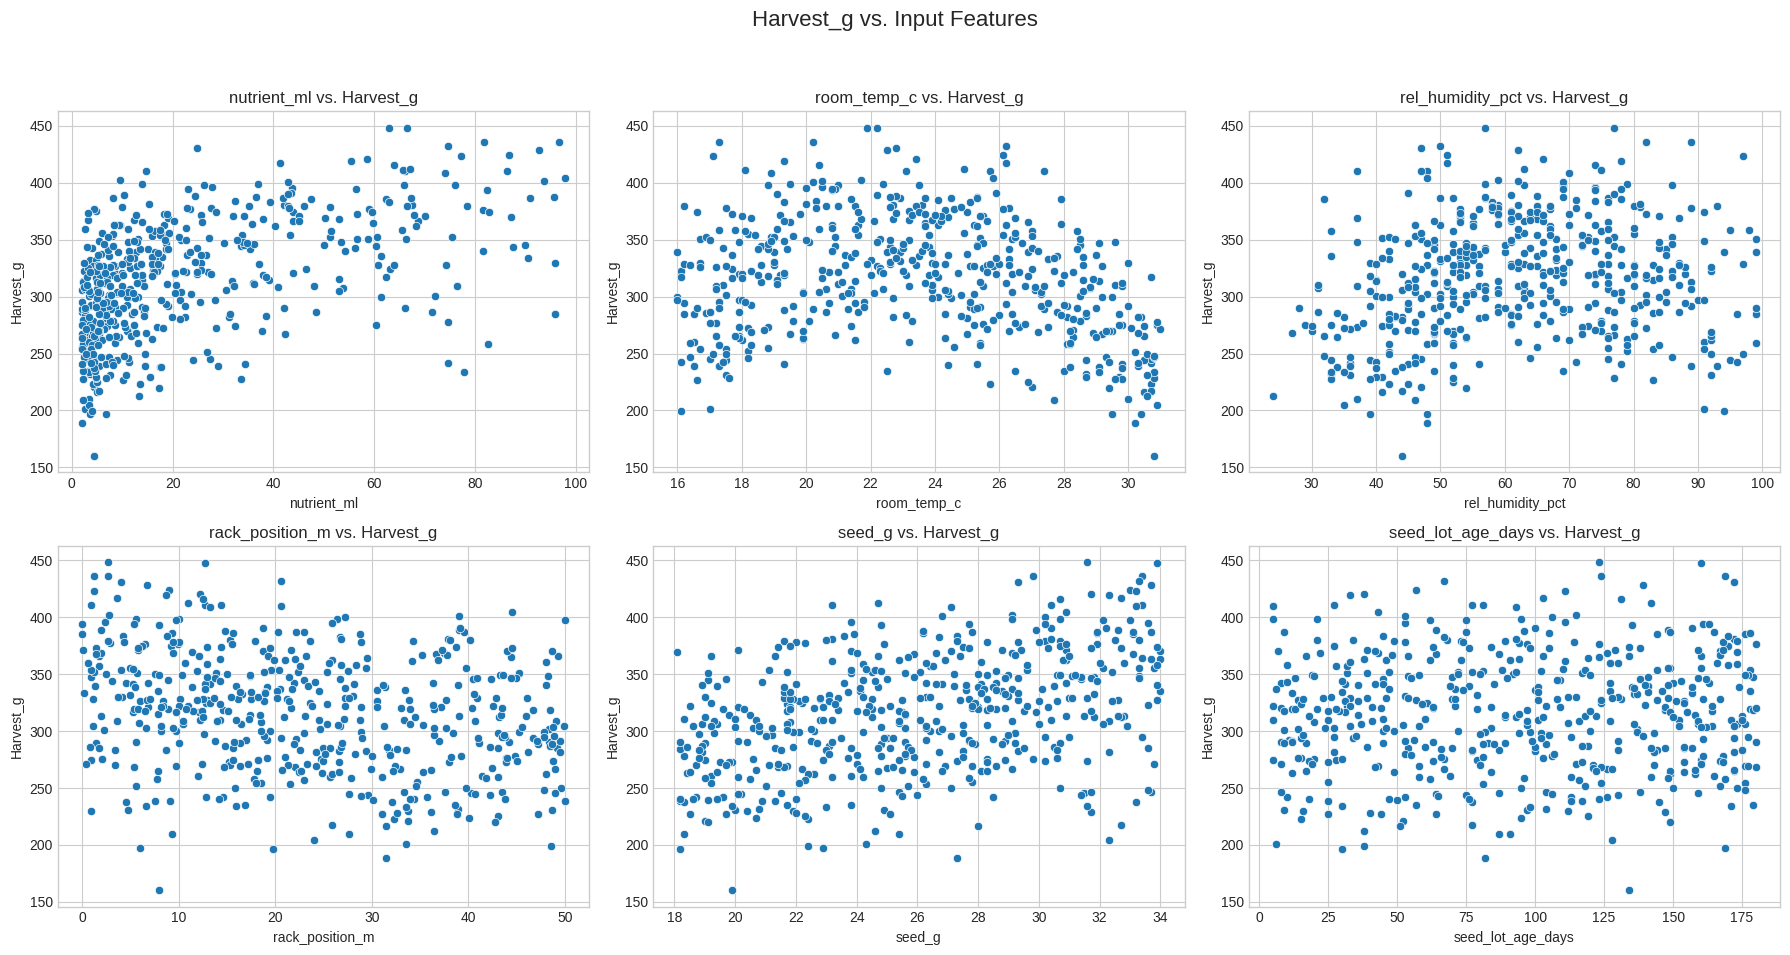

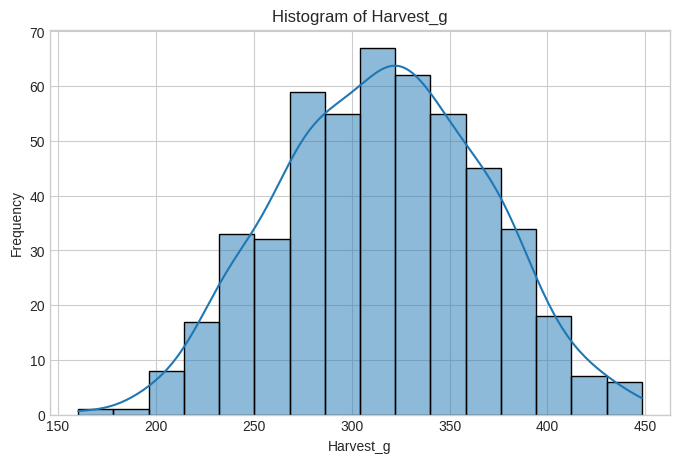

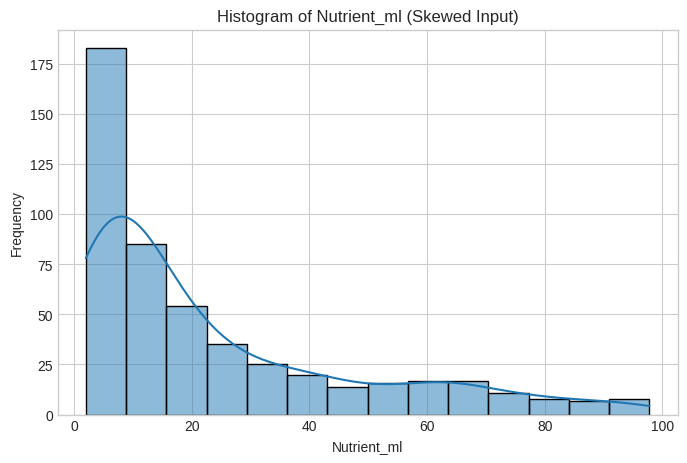

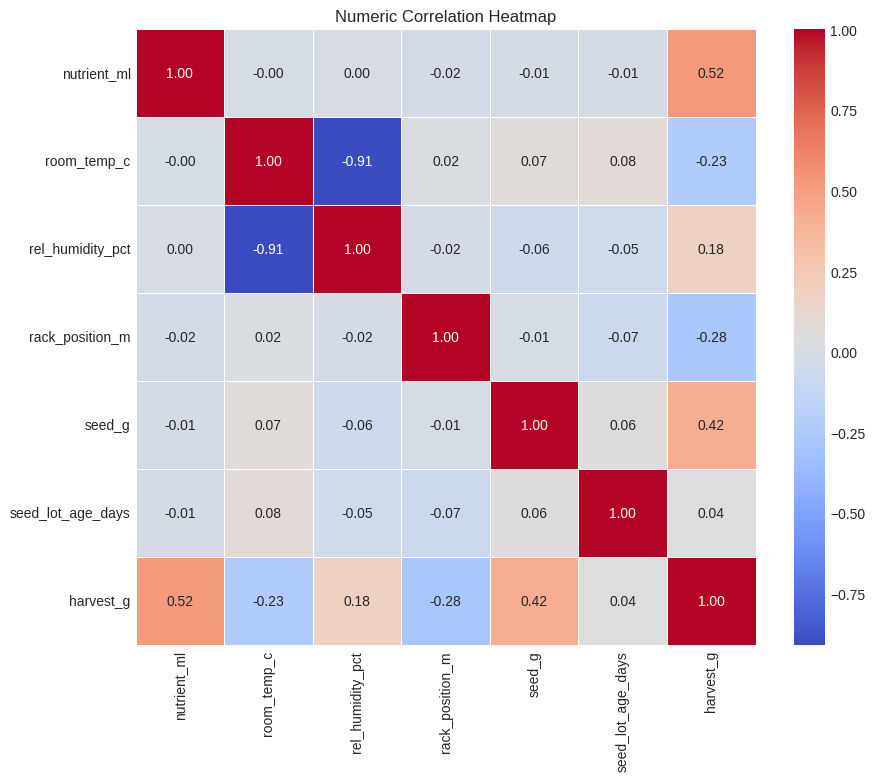

In [3]:
# Print shape
print("DataFrame shape:", df.shape)

# Show dtypes
print("\nDataFrame dtypes:")
print(df.dtypes)

# Show describe()
print("\nDataFrame descriptive statistics:")
print(df.describe())

# Show missing-value counts
print("\nMissing values per column:")
print(df.isnull().sum())

# Draw harvest_g against each of the six inputs in a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Harvest_g vs. Input Features', fontsize=16)

for i, col in enumerate(inputs):
    row = i // 3
    col_idx = i % 3
    sns.scatterplot(x=df[col], y=df['harvest_g'], ax=axes[row, col_idx])
    axes[row, col_idx].set_title(f'{col} vs. Harvest_g')
    axes[row, col_idx].set_xlabel(col)
    axes[row, col_idx].set_ylabel('Harvest_g')

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent suptitle overlap
plt.show()

# Draw a histogram of harvest_g
plt.figure(figsize=(8, 5))
sns.histplot(df['harvest_g'], kde=True)
plt.title('Histogram of Harvest_g')
plt.xlabel('Harvest_g')
plt.ylabel('Frequency')
plt.show()

# Draw a histogram of any clearly skewed input (use nutrient_ml)
plt.figure(figsize=(8, 5))
sns.histplot(df['nutrient_ml'], kde=True)
plt.title('Histogram of Nutrient_ml (Skewed Input)')
plt.xlabel('Nutrient_ml')
plt.ylabel('Frequency')
plt.show()

# Draw a numeric correlation heatmap with annotations
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=np.number)
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Numeric Correlation Heatmap')
plt.show()


**Three observations:**

*Your answer here:*

1. **Scatterplot of nutrient_ml vs. harvest_g:** Harvest weight generally increases as nutrient dose increases, but the increase seems to slow at higher nutrient levels. This suggests the relationship may not be perfectly linear.

2. **Scatterplot of room_temp_c vs. harvest_g:** Harvest weight appears higher around the middle temperature range and lower at both very low and very high temperatures. This suggests temperature may have a curved relationship with harvest weight.

3. **Correlation heatmap:** Room temperature and relative humidity have a very strong negative correlation of about **-0.91**. Humidity has a small positive correlation with harvest weight (**0.18**), while temperature has a negative correlation with harvest weight (**-0.23**). Because temperature and humidity are strongly related to each other, the heatmap alone cannot tell us whether humidity truly affects harvest weight.


### 2.2 Split first **(1 pt — Technical Implementation) (2 pts — Verification Trail)**

- **Technical Implementation (1 pt):** run the split below exactly as given.
- **Verification Trail (2 pts):** in the empty cell, verify that there are 350 training trays and
  150 test trays and that **no `tray_id` is on both sides**; then, in one sentence, say why
  `tray_id` is not a feature.

In [4]:
# Split first: hold back 30% of the trays before anything learns from the data. Run as given.
X = df[inputs]
y = df['harvest_g']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train, X_test = X_train.copy(), X_test.copy()   # copies, so you can add new columns to them safely
print(f"Training trays: {len(X_train)}   Test trays: {len(X_test)}")

Training trays: 350   Test trays: 150


In [5]:
# Verify the number of training and test trays
assert len(X_train) == 350, f"Expected 350 training trays, but got {len(X_train)}"
assert len(X_test) == 150, f"Expected 150 test trays, but got {len(X_test)}"
print(f"Verified: {len(X_train)} training trays and {len(X_test)} test trays.")

# Get tray_ids for training and test sets
train_tray_ids = set(df.loc[X_train.index, 'tray_id'])
test_tray_ids = set(df.loc[X_test.index, 'tray_id'])

# Verify no tray_id appears in both sets
common_tray_ids = train_tray_ids.intersection(test_tray_ids)
assert len(common_tray_ids) == 0, f"Found {len(common_tray_ids)} common tray_ids between train and test sets: {common_tray_ids}"
print("Verified: No tray_id appears in both training and test sets.")


Verified: 350 training trays and 150 test trays.
Verified: No tray_id appears in both training and test sets.


**Why `tray_id` is not a feature:**

*Your answer here:*

`tray_id` is only a unique label for each tray. It does not describe anything about how the tray was grown, so it should not be used to predict `harvest_g`.


---

## Part 3: The discovery trail

This part is the heart of the assignment. Most of its points are for the **evidence** that led to
each piece of the equation, so they cannot be earned from a final equation alone. Work one change
at a time, biggest pattern first. After every change: residuals against every input, one sentence
about what you see, and a new row in the growing table.

### 3.1 Start simple **(2 pts — Technical Implementation) (1 pt — Verification Trail) (2 pts — Understanding)**

- **Technical Implementation (2 pts):** fit `LinearRegression` on all six inputs as straight
  lines, add its row with `score`, and show the intercept, the **raw** coefficients and the
  **standardized** coefficients.
- **Verification Trail (1 pt):** `plot_residuals`, with a sentence about each input's panel.
- **Understanding (2 pts):** name the **biggest** pattern and the column it calls for. If Wes and
  Alicia saw only this model's coefficients, what would each of them conclude?

In [6]:
results = {}

def score(name, model, X_train_cols, X_test_cols):
    train_pred = model.predict(X_train_cols)
    test_pred = model.predict(X_test_cols)

    results[name] = {
        'columns': X_train_cols.shape[1],
        'train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'test R²': r2_score(y_test, test_pred)
    }

    return pd.DataFrame(results).T.round(3)

In [7]:
columns = inputs.copy()

model_1 = LinearRegression().fit(
    X_train[columns],
    y_train
)

score(
    '1 - all six inputs, straight lines',
    model_1,
    X_train[columns],
    X_test[columns]
)

,columns,train RMSE,test RMSE,test R²
"1 - all six inputs, straight lines",6.0,32.329,34.654,0.583


In [8]:
# Model intercept
intercept = model_1.intercept_

# Raw coefficients
raw_coefficients = pd.Series(model_1.coef_, index=columns)

# Standardized coefficients
# Fit StandardScaler only on X_train for the relevant columns
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train[columns])

# Fit a new LinearRegression model on the scaled data
model_scaled = LinearRegression().fit(X_train_scaled, y_train)
standardized_coefficients = pd.Series(model_scaled.coef_, index=columns)

# Create a DataFrame to display the results
coef_df = pd.DataFrame({
    'Raw Coefficient': raw_coefficients,
    'Standardized Coefficient': standardized_coefficients
})

print(f"Model Intercept: {intercept:.3f}")
print("\nCoefficients:")
print(coef_df)


Model Intercept: 351.421

Coefficients:
                   Raw Coefficient  Standardized Coefficient
nutrient_ml               1.030115                 24.360746
room_temp_c              -5.902457                -25.243046
rel_humidity_pct         -0.637986                -10.787072
rack_position_m          -0.907783                -13.167759
seed_g                    5.215682                 23.729462
seed_lot_age_days         0.020952                  1.113409


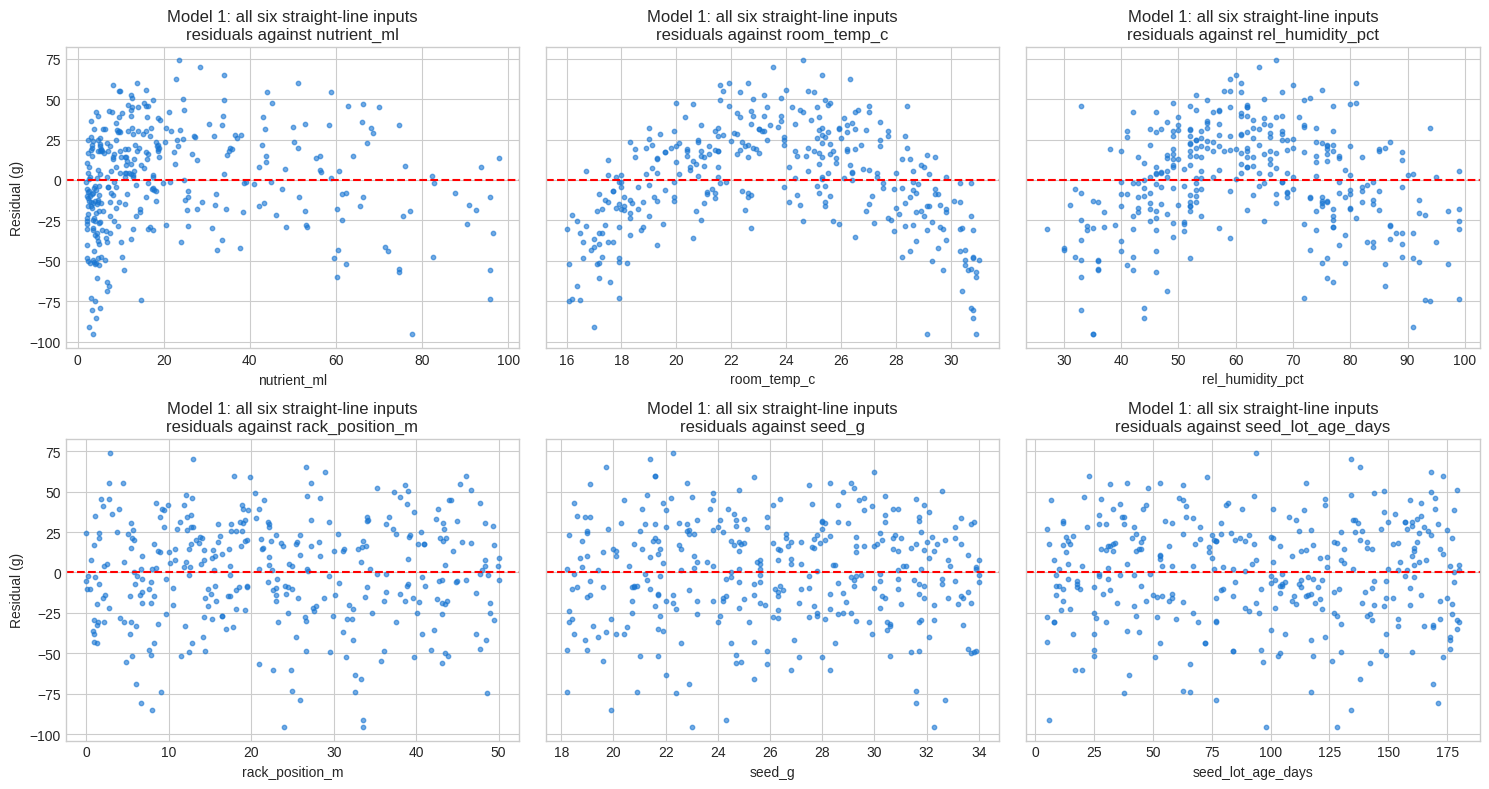

In [9]:
plot_residuals(model_1, X_train[columns], 'Model 1: all six straight-line inputs')

**What the residual plots show, the biggest pattern, and what Wes and Alicia would conclude:**

*Your answer here:*

* **nutrient_ml:** The residuals still show some pattern, so a straight line may not fully describe the nutrient effect.
* **room_temp_c:** The residuals show a strong curved pattern, with positive residuals in the middle and negative residuals at low and high temperatures.
* **rel_humidity_pct:** The residuals also show a curved pattern, but humidity is strongly related to temperature, so this may be caused by the missing temperature curve.
* **rack_position_m:** The residuals show some repeating up-and-down movement, suggesting rack position may need a different shape later.
* **seed_g:** The residuals look mostly random around zero, so the straight-line effect seems reasonable.
* **seed_lot_age_days:** The residuals look mostly random with no strong pattern.

The **biggest pattern is the curved pattern for `room_temp_c`**. This suggests that temperature needs a nonlinear term, such as temperature squared.

If Wes looked only at this model's coefficients, he would see a negative temperature coefficient of about **-5.90**, so he might conclude that warmer temperatures reduce harvest weight. He would also see a very small positive coefficient for seed lot age, which does not support his belief that older seed lots perform worse.

If Alicia looked only at the coefficients, she would see a negative humidity coefficient of about **-0.64** and might conclude that higher humidity reduces harvest weight. However, this may be misleading because humidity and temperature are strongly related and the temperature relationship is not yet modeled correctly.


### 3.2 Each curved piece you add **(6 pts — Technical Implementation) (4 pts — Verification Trail) (4 pts — Understanding)**

Repeat this loop for **each** curved piece (a bend or an arch) the residuals show you:

1. The residual plot that motivated it, and one sentence about the shape you see.
2. **At most three** candidate columns, compared on test RMSE with `score`; at least one rejected.
3. The new table row, and the residual plot **after** the change.
4. **In your own words:** why that shape? (What tells a symmetric U or arch apart from a lopsided
   bend, and why keep x beside x²?)

- **Technical Implementation (6 pts):** each curved piece you keep has the right shape, and its
  columns are computed the same way on the training and test rows.
- **Verification Trail (4 pts):** the motivating plot, the candidates judged on test RMSE with at
  least one rejected, and the plot after, for each piece.
- **Understanding (4 pts):** why that shape, for each piece.

Add as many code and markdown cells as you need.

First Curved Piece - Candidate Comparison:
                                    columns  train RMSE  test RMSE  test R²
1 - all six inputs, straight lines      6.0      32.329     34.654    0.583
1 - baseline + room_temp_c_sq           7.0      21.346     21.673    0.837
1 - baseline + room_temp_c_log          7.0      21.526     22.020    0.832
1 - baseline + rel_humidity_pct_sq      7.0      27.479     29.598    0.696

Model 2 (with room_temp_c_sq) added to results:
                                    columns  train RMSE  test RMSE  test R²
1 - all six inputs, straight lines      6.0      32.329     34.654    0.583
1 - baseline + room_temp_c_sq           7.0      21.346     21.673    0.837
1 - baseline + room_temp_c_log          7.0      21.526     22.020    0.832
1 - baseline + rel_humidity_pct_sq      7.0      27.479     29.598    0.696
2 - model_1 + room_temp_c_sq            7.0      21.346     21.673    0.837


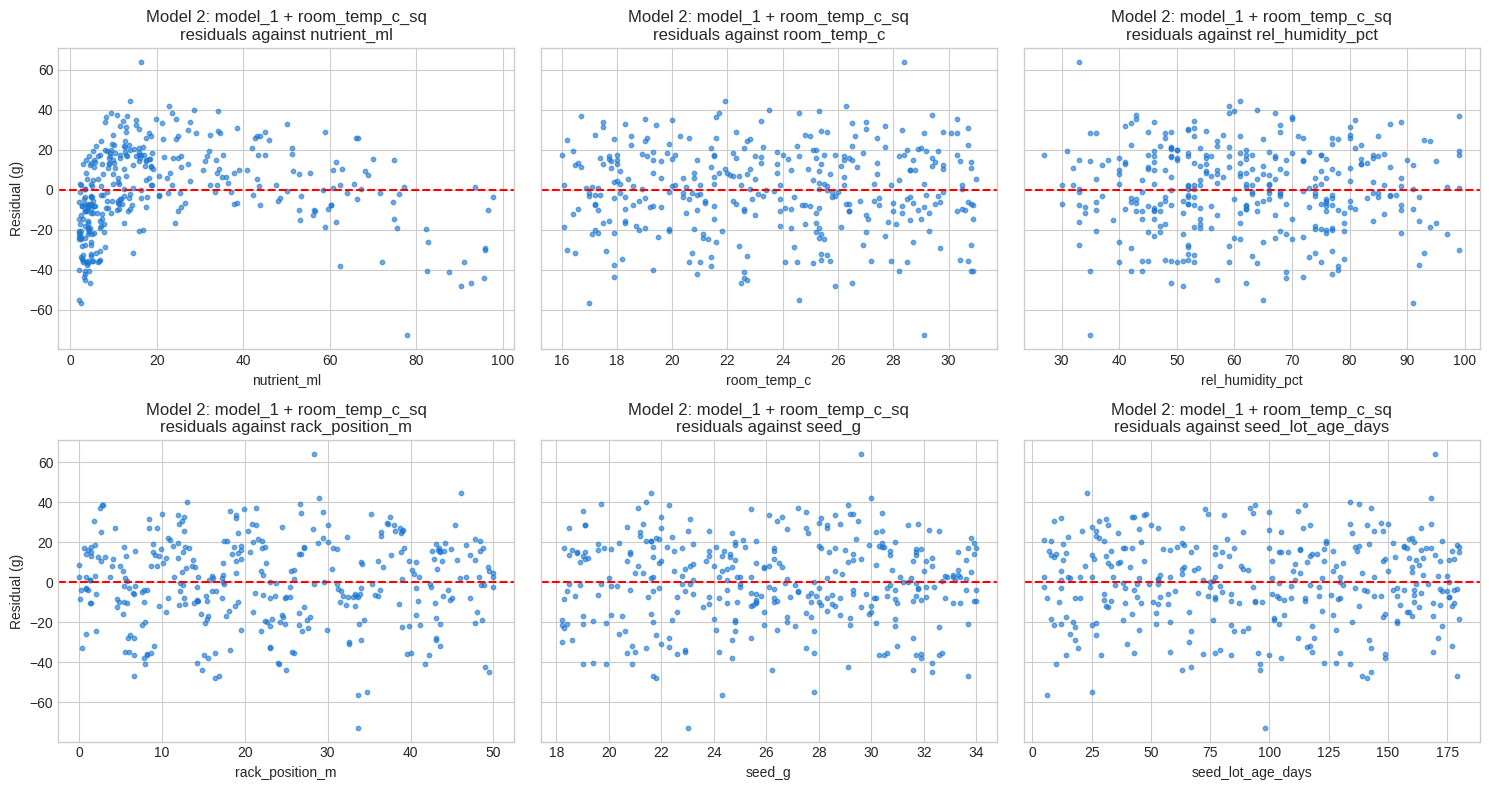


Second Curved Piece - Candidate Comparison (building on Model 2):
                                    columns  train RMSE  test RMSE  test R²
1 - all six inputs, straight lines      6.0      32.329     34.654    0.583
1 - baseline + room_temp_c_sq           7.0      21.346     21.673    0.837
1 - baseline + room_temp_c_log          7.0      21.526     22.020    0.832
1 - baseline + rel_humidity_pct_sq      7.0      27.479     29.598    0.696
2 - model_1 + room_temp_c_sq            7.0      21.346     21.673    0.837
2 - model_2 + nutrient_log              8.0      16.659     18.112    0.886
2 - model_2 + nutrient_sq               8.0      18.029     19.680    0.865
2 - model_2 + nutrient_cube             8.0      18.838     20.207    0.858

Model 3 (with nutrient_log) added to results:
                                    columns  train RMSE  test RMSE  test R²
1 - all six inputs, straight lines      6.0      32.329     34.654    0.583
1 - baseline + room_temp_c_sq           7.0      2

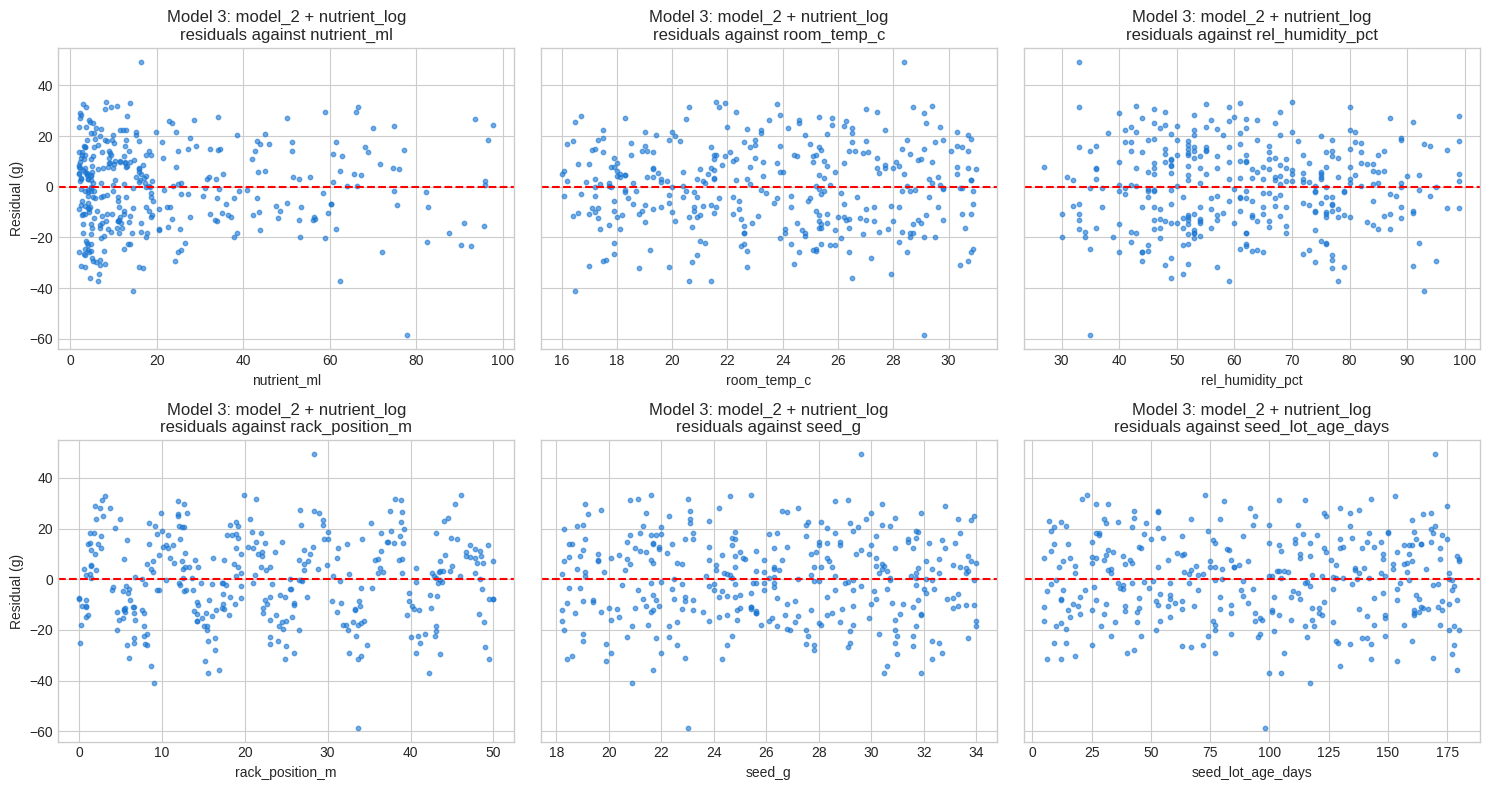

In [10]:
# First curved piece: candidates for room_temp_c and rel_humidity_pct
# Compute candidate columns identically on train and test
X_train['room_temp_c_sq'] = X_train['room_temp_c']**2
X_test['room_temp_c_sq'] = X_test['room_temp_c']**2

X_train['room_temp_c_log'] = np.log(X_train['room_temp_c'])
X_test['room_temp_c_log'] = np.log(X_test['room_temp_c'])

X_train['rel_humidity_pct_sq'] = X_train['rel_humidity_pct']**2
X_test['rel_humidity_pct_sq'] = X_test['rel_humidity_pct']**2

# Fit each candidate by adding exactly one column to the six-input baseline
# and call score() for each.
candidate_features_1 = [
    'room_temp_c_sq',
    'room_temp_c_log',
    'rel_humidity_pct_sq'
]

print("First Curved Piece - Candidate Comparison:")
for cand_col in candidate_features_1:
    current_columns = inputs.copy() + [cand_col]
    model = LinearRegression().fit(X_train[current_columns], y_train)
    # Renaming existing score entry if it refers to the same model (e.g. initial baseline)
    score_name = f'1 - baseline + {cand_col}'
    score(score_name, model, X_train[current_columns], X_test[current_columns])

# Show the small candidate table (all results so far)
print(pd.DataFrame(results).T.round(3))

# Keep room_temp_c_sq as model_2 / columns_2
columns_2 = inputs.copy() + ['room_temp_c_sq']
model_2 = LinearRegression().fit(X_train[columns_2], y_train)
score('2 - model_1 + room_temp_c_sq', model_2, X_train[columns_2], X_test[columns_2])

print("\nModel 2 (with room_temp_c_sq) added to results:")
print(pd.DataFrame(results).T.round(3))

# Call plot_residuals()
plot_residuals(model_2, X_train[columns_2], 'Model 2: model_1 + room_temp_c_sq')


# Second curved piece: candidates for nutrient_ml
# Compute candidate columns identically on train and test
X_train['nutrient_log'] = np.log(X_train['nutrient_ml'])
X_test['nutrient_log'] = np.log(X_test['nutrient_ml'])

X_train['nutrient_sq'] = X_train['nutrient_ml']**2
X_test['nutrient_sq'] = X_test['nutrient_ml']**2

X_train['nutrient_cube'] = X_train['nutrient_ml']**3
X_test['nutrient_cube'] = X_test['nutrient_ml']**3

print("\nSecond Curved Piece - Candidate Comparison (building on Model 2):")
candidate_features_2 = [
    'nutrient_log',
    'nutrient_sq',
    'nutrient_cube'
]

for cand_col in candidate_features_2:
    current_columns = columns_2 + [cand_col]
    model = LinearRegression().fit(X_train[current_columns], y_train)
    score_name = f'2 - model_2 + {cand_col}'
    score(score_name, model, X_train[current_columns], X_test[current_columns])

# Show the candidate table (all results so far)
print(pd.DataFrame(results).T.round(3))

# Keep nutrient_log as model_3 / columns_3
columns_3 = columns_2 + ['nutrient_log']
model_3 = LinearRegression().fit(X_train[columns_3], y_train)
score('3 - model_2 + nutrient_log', model_3, X_train[columns_3], X_test[columns_3])

print("\nModel 3 (with nutrient_log) added to results:")
print(pd.DataFrame(results).T.round(3))

# Call plot_residuals() again
plot_residuals(model_3, X_train[columns_3], 'Model 3: model_2 + nutrient_log')


**For each piece: the pattern, the candidates, what the plot after shows, and why that shape:**

*Your answer here:*

**First curved piece — temperature:**
The Model 1 residual plot showed a clear arch for `room_temp_c`: residuals were negative at low and high temperatures and positive near the middle. I compared temperature squared, temperature log, and humidity squared. `room_temp_c_sq` gave the lowest test RMSE at **21.673**, compared with **22.020** for temperature log and **29.598** for humidity squared, so I kept temperature squared.

After adding it, the strong temperature curve mostly disappeared. I used a quadratic because the original pattern looked like a fairly symmetric arch. I kept `room_temp_c` together with `room_temp_c_sq` because the linear and squared terms together allow the peak of the curve to occur at the correct temperature instead of forcing it to a fixed location.

**Second curved piece — nutrient:**
After fixing temperature, the residual plot for `nutrient_ml` still showed a lopsided bend. The change was stronger at low nutrient amounts and became flatter as nutrient increased. I compared log, square, and cube transformations. `nutrient_log` had the lowest test RMSE at **18.112**, compared with **19.680** for nutrient squared and **20.207** for nutrient cubed, so I kept the log transformation.

After adding `nutrient_log`, the nutrient pattern became much smaller. A log shape makes sense because the effect rises quickly at low nutrient levels and then slows down at higher levels. This is different from the more symmetric arch seen for temperature.

After both changes, the clearest pattern left is the repeating up-and-down pattern in `rack_position_m`, which should be investigated next.


### 3.3 A repeating wave **(4 pts — Technical Implementation) (2 pts — Verification Trail) (3 pts — Understanding)**

When a residual plot shows a regular wave (peaks evenly spaced along one input):

1. `zoom_residuals` on that column, passing a smaller `step` until you can place each peak within
   one gridline; list where you read each peak.
2. The period arithmetic.
3. Candidate periods, each with both a sine and a cosine column, compared on test RMSE in the **two
   passes** from the reminders: a coarse pass around your estimate, then a fine pass around its
   winner. That is **at most seven** candidate periods; stop there.
4. One row with **only a sine** column at your best period, against sine + cosine.
5. The residual plots after.
6. **In your own words:** why both columns, and why only a few candidates?

- **Technical Implementation (4 pts):** correct wave columns, and a period that the evidence
  supports.
- **Verification Trail (2 pts):** the zoomed plot with your peak readings, and the candidate
  comparison.
- **Understanding (3 pts):** why both columns (2), and why only a few candidates (1).

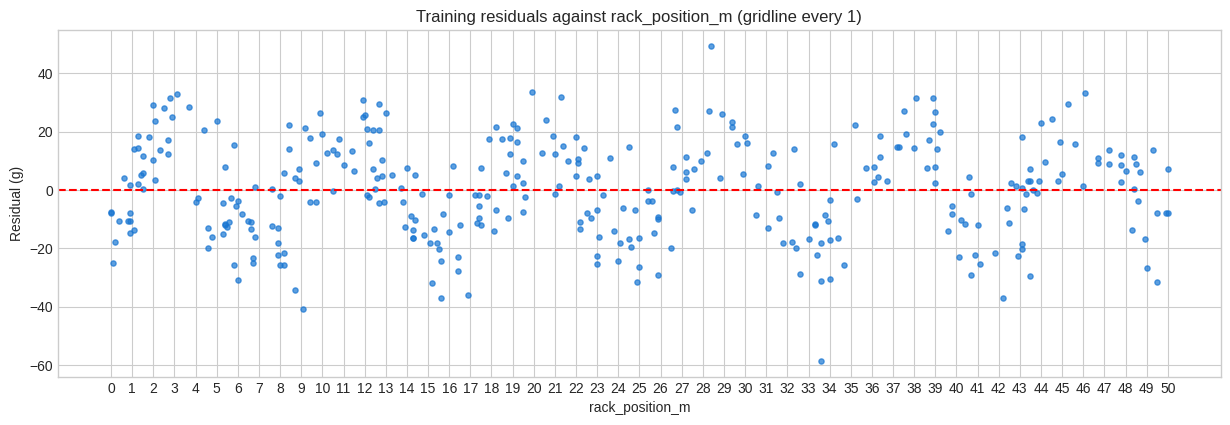

In [11]:
zoom_residuals(model_3, X_train[columns_3], 'rack_position_m', step=1)

In [12]:
# Peak locations estimated from the zoom_residuals plot for rack_position_m
peak_locations = [3, 12, 20, 29, 38, 46]

first_peak = peak_locations[0]
last_peak = peak_locations[-1]
number_of_peaks = len(peak_locations)

estimated_period = (last_peak - first_peak) / (number_of_peaks - 1)

print("Estimated peak locations (m):", peak_locations)
print(f"Estimated period: ({last_peak} - {first_peak}) / ({number_of_peaks} - 1) = {estimated_period:.1f} m")

Estimated peak locations (m): [3, 12, 20, 29, 38, 46]
Estimated period: (46 - 3) / (6 - 1) = 8.6 m


In [13]:
# Estimated period from the zoomed residual plot
estimated_period = 8.6

# Coarse pass
coarse_step = estimated_period / 5
coarse_periods = [
    estimated_period - coarse_step,
    estimated_period,
    estimated_period + coarse_step
]

period_results = {}

for P in coarse_periods:
    sin_col = f'rack_sin_{P:.3f}'
    cos_col = f'rack_cos_{P:.3f}'

    X_train[sin_col] = np.sin(2 * np.pi * X_train['rack_position_m'] / P)
    X_test[sin_col] = np.sin(2 * np.pi * X_test['rack_position_m'] / P)

    X_train[cos_col] = np.cos(2 * np.pi * X_train['rack_position_m'] / P)
    X_test[cos_col] = np.cos(2 * np.pi * X_test['rack_position_m'] / P)

    cols = columns_3 + [sin_col, cos_col]
    model = LinearRegression().fit(X_train[cols], y_train)

    name = f'wave P={P:.3f}'
    score(name, model, X_train[cols], X_test[cols])

    pred = model.predict(X_test[cols])
    period_results[P] = np.sqrt(mean_squared_error(y_test, pred))

best_coarse = min(period_results, key=period_results.get)

print("Coarse periods:", coarse_periods)
print("Best coarse period:", round(best_coarse, 3))


# Fine pass around the coarse winner
fine_step = coarse_step / 5
fine_periods = [
    best_coarse - fine_step,
    best_coarse + fine_step
]

for P in fine_periods:
    sin_col = f'rack_sin_{P:.3f}'
    cos_col = f'rack_cos_{P:.3f}'

    X_train[sin_col] = np.sin(2 * np.pi * X_train['rack_position_m'] / P)
    X_test[sin_col] = np.sin(2 * np.pi * X_test['rack_position_m'] / P)

    X_train[cos_col] = np.cos(2 * np.pi * X_train['rack_position_m'] / P)
    X_test[cos_col] = np.cos(2 * np.pi * X_test['rack_position_m'] / P)

    cols = columns_3 + [sin_col, cos_col]
    model = LinearRegression().fit(X_train[cols], y_train)

    name = f'wave P={P:.3f}'
    score(name, model, X_train[cols], X_test[cols])

    pred = model.predict(X_test[cols])
    period_results[P] = np.sqrt(mean_squared_error(y_test, pred))


# Best period from all tested periods
best_period = min(period_results, key=period_results.get)

print("Fine periods:", fine_periods)
print("Best period:", round(best_period, 3))
print("Best test RMSE:", round(period_results[best_period], 3))


# Build final sine + cosine model
best_sin = f'rack_sin_{best_period:.3f}'
best_cos = f'rack_cos_{best_period:.3f}'

columns_4 = columns_3 + [best_sin, best_cos]

model_4 = LinearRegression().fit(
    X_train[columns_4],
    y_train
)

score(
    '4 - model_3 + rack wave',
    model_4,
    X_train[columns_4],
    X_test[columns_4]
)


# Compare sine-only with sine + cosine
sine_only_columns = columns_3 + [best_sin]

sine_only_model = LinearRegression().fit(
    X_train[sine_only_columns],
    y_train
)

score(
    'sine only',
    sine_only_model,
    X_train[sine_only_columns],
    X_test[sine_only_columns]
)

score(
    'sine + cosine',
    model_4,
    X_train[columns_4],
    X_test[columns_4]
)

pd.DataFrame(results).T.round(3)

Coarse periods: [6.88, 8.6, 10.32]
Best coarse period: 8.6
Fine periods: [8.256, 8.943999999999999]
Best period: 8.6
Best test RMSE: 11.79


,columns,train RMSE,test RMSE,test R²
"1 - all six inputs, straight lines",6.0,32.329,34.654,0.583
1 - baseline + room_temp_c_sq,7.0,21.346,21.673,0.837
1 - baseline + room_temp_c_log,7.0,21.526,22.020,0.832
1 - baseline + rel_humidity_pct_sq,7.0,27.479,29.598,0.696
2 - model_1 + room_temp_c_sq,7.0,21.346,21.673,0.837
2 - model_2 + nutrient_log,8.0,16.659,18.112,0.886
2 - model_2 + nutrient_sq,8.0,18.029,19.680,0.865
2 - model_2 + nutrient_cube,8.0,18.838,20.207,0.858
3 - model_2 + nutrient_log,8.0,16.659,18.112,0.886
wave P=6.880,10.0,16.384,18.261,0.884


In [14]:
old_rows = [
    '3 - model_3 + wave_P_3.20',
    '3 - model_3 + wave_P_4.00',
    '3 - model_3 + wave_P_4.80',
    '3 - model_3 + wave_P_3.84_fine',
    '3 - model_3 + wave_P_4.00_fine',
    '3 - model_3 + wave_P_4.16_fine',
    'Sine_only_P_3.84',
    'Sine_Cosine_P_3.84'
]

for row in old_rows:
    results.pop(row, None)

results.pop('4 - model_3 + rack_wave', None)
pd.DataFrame(results).T.round(3)

,columns,train RMSE,test RMSE,test R²
"1 - all six inputs, straight lines",6.0,32.329,34.654,0.583
1 - baseline + room_temp_c_sq,7.0,21.346,21.673,0.837
1 - baseline + room_temp_c_log,7.0,21.526,22.020,0.832
1 - baseline + rel_humidity_pct_sq,7.0,27.479,29.598,0.696
2 - model_1 + room_temp_c_sq,7.0,21.346,21.673,0.837
2 - model_2 + nutrient_log,8.0,16.659,18.112,0.886
2 - model_2 + nutrient_sq,8.0,18.029,19.680,0.865
2 - model_2 + nutrient_cube,8.0,18.838,20.207,0.858
3 - model_2 + nutrient_log,8.0,16.659,18.112,0.886
wave P=6.880,10.0,16.384,18.261,0.884


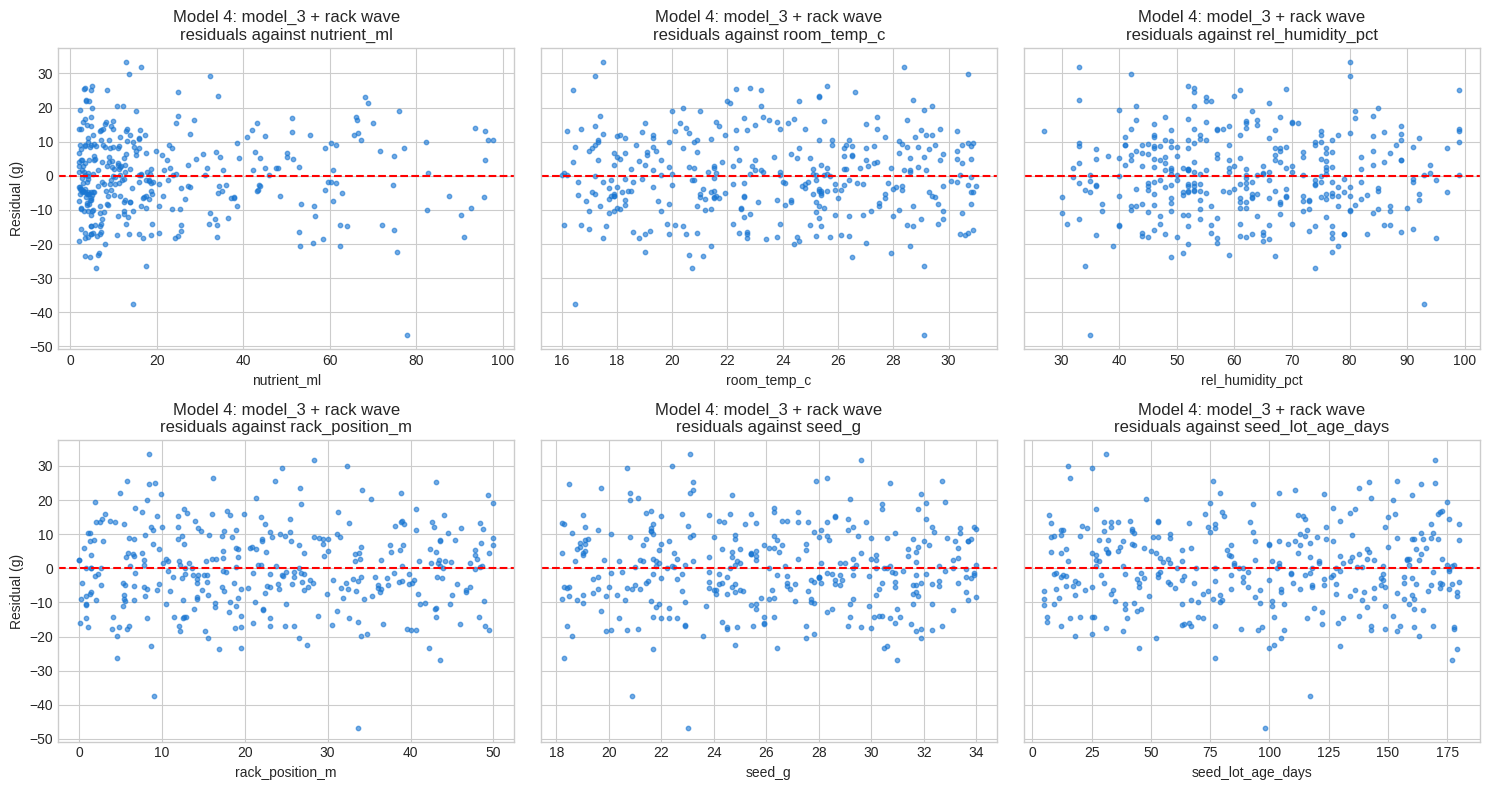

In [15]:
# Plot residuals for Model 4
plot_residuals(
    model_4,
    X_train[columns_4],
    'Model 4: model_3 + rack wave'
)

**Your peaks, your period, and why both columns and only a few candidates:**

*Your answer here:*

The rack-position residual plot showed peaks at about **3, 12, 20, 29, 38, and 46 m**. I estimated the period as **(46 - 3) / (6 - 1) = 8.6 m**.

I tested **6.88, 8.60, and 10.32 m** in the coarse pass. The best was **8.60 m**. I then tested **8.256 and 8.944 m** in the fine pass, but **8.60 m** still had the lowest test RMSE.

Using both sine and cosine at 8.6 m reduced test RMSE from **18.112 to 11.790** and increased test R² to **0.952**. The sine-only model had a higher RMSE of **14.355**.

Both sine and cosine are needed because together they let the wave shift so the peaks occur at the correct rack positions. I tested only a few periods because checking too many values on the test set can lead to overfitting.

After adding the wave, the residual plots are mostly random around zero with no clear repeating pattern.


### 3.4 Discovery log **(2 pts — Verification Trail)**

One row per change, kept or rejected.

| #  | Plot you looked at                       | Pattern seen                                                    | Column(s) tried           | Train / test RMSE | Kept or rejected, and why                                                                         |
| -- | ---------------------------------------- | --------------------------------------------------------------- | ------------------------- | ----------------- | ------------------------------------------------------------------------------------------------- |
| 1  | Model 1 residuals vs. `room_temp_c`      | Strong curved arch                                              | `room_temp_c_sq`          | 21.346 / 21.673   | **Kept.** It gave the lowest test RMSE and removed most of the temperature curve.                 |
| 2  | Model 1 residuals vs. `room_temp_c`      | Strong curved arch                                              | `room_temp_c_log`         | 21.526 / 22.020   | **Rejected.** It was slightly worse than temperature squared.                                     |
| 3  | Model 1 residuals vs. `rel_humidity_pct` | Curved pattern, but humidity is strongly related to temperature | `rel_humidity_pct_sq`     | 27.479 / 29.598   | **Rejected.** Test RMSE was much higher than temperature squared.                                 |
| 4  | Model 2 residuals vs. `nutrient_ml`      | Strong effect at low nutrient levels that becomes flatter       | `nutrient_log`            | 16.659 / 18.112   | **Kept.** It had the lowest test RMSE and reduced the nutrient pattern.                           |
| 5  | Model 2 residuals vs. `nutrient_ml`      | Curved nutrient pattern                                         | `nutrient_sq`             | 18.029 / 19.680   | **Rejected.** Test RMSE was higher than the log model.                                            |
| 6  | Model 2 residuals vs. `nutrient_ml`      | Curved nutrient pattern                                         | `nutrient_cube`           | 18.838 / 20.207   | **Rejected.** It performed worse than the log model.                                              |
| 7  | Model 3 residuals vs. `rack_position_m`  | Clear repeating wave                                            | sin + cos, P = 6.88 m     | 16.384 / 18.261   | **Rejected.** Test RMSE stayed high.                                                              |
| 8  | Model 3 residuals vs. `rack_position_m`  | Clear repeating wave                                            | sin + cos, P = 8.60 m     | 12.010 / 11.790   | **Kept.** It gave the lowest test RMSE and removed the repeating pattern.                         |
| 9  | Model 3 residuals vs. `rack_position_m`  | Clear repeating wave                                            | sin + cos, P = 10.32 m    | 16.492 / 17.915   | **Rejected.** Test RMSE was much higher than 8.60 m.                                              |
| 10 | Fine search around 8.60 m                | Checking nearby periods                                         | sin + cos, P = 8.256 m    | 13.450 / 13.289   | **Rejected.** It was good, but worse than 8.60 m.                                                 |
| 11 | Fine search around 8.60 m                | Checking nearby periods                                         | sin + cos, P = 8.944 m    | 12.759 / 12.955   | **Rejected.** It was close, but still worse than 8.60 m.                                          |
| 12 | Rack wave comparison                     | Test whether cosine is needed                                   | sine only, P = 8.60 m     | 13.786 / 14.355   | **Rejected.** Sine alone could not fit the wave as well.                                          |
| 13 | Rack wave comparison                     | Same wave with more flexible position                           | sine + cosine, P = 8.60 m | 12.010 / 11.790   | **Kept.** It had the best test RMSE, and the final residual plots were mostly random around zero. |


---

## Part 4: Enough, and what doesn't matter

### 4.1 Have you gone too far? **(2 pts — Technical Implementation) (1 pt — Verification Trail)**

- **Technical Implementation (2 pts):** add **at least two** extra candidates to your best model,
  **one at a time** (for example a higher power, or a column you have not used), and score each.
- **Verification Trail (1 pt):** read training RMSE against test RMSE for each, and say whether it
  earned its place.

In [16]:
# Add room_temp_c_cube as a candidate
X_train['room_temp_c_cube'] = X_train['room_temp_c']**3
X_test['room_temp_c_cube'] = X_test['room_temp_c']**3

candidate_columns_1 = columns_4 + ['room_temp_c_cube']
model_candidate_1 = LinearRegression().fit(X_train[candidate_columns_1], y_train)
score('4 - model_4 + room_temp_c_cube', model_candidate_1, X_train[candidate_columns_1], X_test[candidate_columns_1])

# Add seed_g_sq as a candidate
X_train['seed_g_sq'] = X_train['seed_g']**2
X_test['seed_g_sq'] = X_test['seed_g']**2

candidate_columns_2 = columns_4 + ['seed_g_sq']
model_candidate_2 = LinearRegression().fit(X_train[candidate_columns_2], y_train)
score('4 - model_4 + seed_g_sq', model_candidate_2, X_train[candidate_columns_2], X_test[candidate_columns_2])

# Display a small table containing the current best model and these two new candidates
comparison_rows = [
    '4 - model_3 + rack wave', # Current best model
    '4 - model_4 + room_temp_c_cube',
    '4 - model_4 + seed_g_sq'
]
print("\nCandidate comparison for extra features (with Model 4):")
print(pd.DataFrame(results).T.loc[comparison_rows].round(3))


Candidate comparison for extra features (with Model 4):
                                columns  train RMSE  test RMSE  test R²
4 - model_3 + rack wave            10.0      12.010     11.790    0.952
4 - model_4 + room_temp_c_cube     11.0      12.009     11.801    0.952
4 - model_4 + seed_g_sq            11.0      12.008     11.802    0.952


*Your reading:*

I tested two extra features: `room_temp_c_cube` and `seed_g_sq`.

Adding `room_temp_c_cube` slightly lowered training RMSE from **12.010 to 12.009**, but test RMSE increased from **11.790 to 11.801**. I rejected it because it did not improve performance on unseen data.

Adding `seed_g_sq` also slightly lowered training RMSE to **12.008**, but test RMSE increased to **11.802**. I rejected it for the same reason.

Neither extra feature earned a place in the model. The small training improvements with slightly worse test results suggest that adding more complexity is not helping.


### 4.2 Correlated columns and the drop test **(3 pts — Technical Implementation) (1 pt — Verification Trail)**

1. **Check for correlation first.** For each column you suspect contributes nothing, show how strongly
   it moves with each of the other inputs on the training rows (a correlation table, or your heatmap
   from 2.1). A column that moves with a real one can borrow that column's credit in a straight-line
   model: this week's multicollinearity.
2. **The drop test.** Remove the suspect column(s) one at a time and together, and compare test RMSE
   with the model that keeps them. For contrast, drop **one column you are sure matters** too.
3. **Decide.** For each column you tested, keep it or drop it, citing the table row that decided it.

How big a change counts? On 150 test trays, a change of a few hundredths of a gram is noise. Keep a
column only if dropping it raises test RMSE by clearly more than that, for example by **over 1%**.

In [17]:
# 1. Display the training correlation matrix for the six original inputs
print("Training correlation matrix for original inputs:")
print(X_train[inputs].corr().round(3))

# 2. Print the correlation between nutrient_ml and nutrient_log
corr_nutrient_ml_log = X_train['nutrient_ml'].corr(X_train['nutrient_log'])
print(f"\nCorrelation between nutrient_ml and nutrient_log: {corr_nutrient_ml_log:.3f}")

# Base columns for drop tests (current best model: model_4/columns_4)
base_columns = columns_4.copy() # Make a copy to avoid modifying columns_4 directly

# Perform drop tests
print("\n--- Drop Tests ---")

# Drop rel_humidity_pct only
cols_drop_humidity = [col for col in base_columns if col != 'rel_humidity_pct']
model_drop_humidity = LinearRegression().fit(X_train[cols_drop_humidity], y_train)
score('Drop: rel_humidity_pct', model_drop_humidity, X_train[cols_drop_humidity], X_test[cols_drop_humidity])

# Drop seed_lot_age_days only
cols_drop_seed_age = [col for col in base_columns if col != 'seed_lot_age_days']
model_drop_seed_age = LinearRegression().fit(X_train[cols_drop_seed_age], y_train)
score('Drop: seed_lot_age_days', model_drop_seed_age, X_train[cols_drop_seed_age], X_test[cols_drop_seed_age])

# Drop raw nutrient_ml only (keep nutrient_log)
cols_drop_raw_nutrient = [col for col in base_columns if col != 'nutrient_ml']
model_drop_raw_nutrient = LinearRegression().fit(X_train[cols_drop_raw_nutrient], y_train)
score('Drop: nutrient_ml (raw)', model_drop_raw_nutrient, X_train[cols_drop_raw_nutrient], X_test[cols_drop_raw_nutrient])

# Drop humidity+age
cols_drop_humidity_age = [col for col in base_columns if col not in ['rel_humidity_pct', 'seed_lot_age_days']]
model_drop_humidity_age = LinearRegression().fit(X_train[cols_drop_humidity_age], y_train)
score('Drop: humidity+age', model_drop_humidity_age, X_train[cols_drop_humidity_age], X_test[cols_drop_humidity_age])

# Drop humidity+age+raw nutrient together
cols_drop_all_three = [col for col in base_columns if col not in ['rel_humidity_pct', 'seed_lot_age_days', 'nutrient_ml']]
model_drop_all_three = LinearRegression().fit(X_train[cols_drop_all_three], y_train)
score('Drop: humidity+age+raw_nutrient', model_drop_all_three, X_train[cols_drop_all_three], X_test[cols_drop_all_three])

# For contrast, drop seed_g
cols_drop_seed_g = [col for col in base_columns if col != 'seed_g']
model_drop_seed_g = LinearRegression().fit(X_train[cols_drop_seed_g], y_train)
score('Drop: seed_g (for contrast)', model_drop_seed_g, X_train[cols_drop_seed_g], X_test[cols_drop_seed_g])

# Display all results including the original model_4 and drop test results
# We'll display a summary table at the end with model_4, drop tests, and final model.


# Define the final simplified model
print("\n--- Final Simplified Model Definition ---")

# Features to keep in the final model:
# nutrient_log, both temperature terms (room_temp_c, room_temp_c_sq),
# seed_g, rack_position_m, and the sine/cosine terms (rack_sin_8.600, rack_cos_8.600).
# Exclude: rel_humidity_pct, seed_lot_age_days, raw nutrient_ml.

final_cols = [
    'room_temp_c',
    'room_temp_c_sq',
    'nutrient_log',
    'seed_g',
    'rack_position_m',
    'rack_sin_8.600',
    'rack_cos_8.600'
]

# Fit the final model
final_model = LinearRegression().fit(X_train[final_cols], y_train)
score('Final Model', final_model, X_train[final_cols], X_test[final_cols])

print("\nFinal Model and drop test results (compared to model_4):")
# Display model_4, drop tests, and final model
comparison_rows_final = [
    '4 - model_3 + rack wave', # Original model_4
    'Drop: rel_humidity_pct',
    'Drop: seed_lot_age_days',
    'Drop: nutrient_ml (raw)',
    'Drop: humidity+age',
    'Drop: humidity+age+raw_nutrient',
    'Drop: seed_g (for contrast)',
    'Final Model'
]
print(pd.DataFrame(results).T.loc[comparison_rows_final].round(3))

Training correlation matrix for original inputs:
                   nutrient_ml  room_temp_c  rel_humidity_pct  rack_position_m  seed_g  seed_lot_age_days
nutrient_ml              1.000        0.006            -0.007            0.022  -0.002             -0.024
room_temp_c              0.006        1.000            -0.913            0.010   0.066              0.114
rel_humidity_pct        -0.007       -0.913             1.000           -0.012  -0.059             -0.077
rack_position_m          0.022        0.010            -0.012            1.000   0.004             -0.102
seed_g                  -0.002        0.066            -0.059            0.004   1.000              0.091
seed_lot_age_days       -0.024        0.114            -0.077           -0.102   0.091              1.000

Correlation between nutrient_ml and nutrient_log: 0.899

--- Drop Tests ---

--- Final Simplified Model Definition ---

Final Model and drop test results (compared to model_4):
                               

*Your reading:*

The correlation check shows that `rel_humidity_pct` is strongly related to `room_temp_c`, with a correlation of **-0.913**. This means humidity could appear important because it moves closely with temperature. Raw `nutrient_ml` is also strongly related to `nutrient_log`, with a correlation of **0.899**.

The drop tests show that `rel_humidity_pct`, `seed_lot_age_days`, and raw `nutrient_ml` are not needed. Dropping humidity changed test RMSE from **11.790 to 11.783**, dropping seed-lot age changed it to **11.815**, and dropping raw nutrient changed it to **11.768**. These changes are very small and do not make the model meaningfully worse.

When I dropped all three together, test RMSE was **11.789**, almost exactly the same as the original **11.790**. Therefore, I dropped all three from the final model.

For contrast, dropping `seed_g` increased test RMSE to **26.080**, so `seed_g` clearly matters and should stay.

The final simplified model has **7 columns**, a training RMSE of **12.033**, a test RMSE of **11.789**, and a test R² of **0.952**.


---

## Part 5: The equation and what it means

### 5.1 The final equation **(2 pts — Technical Implementation) (1 pt — Verification Trail)**

- **Technical Implementation (2 pts):** your final model's coefficients as a table in original
  units, intercept included; its test RMSE, MAE and R² next to the naive step-1 model's.
- **Verification Trail (1 pt):** the final residual checks: test residuals against predicted
  values, a histogram of the test residuals, and training residuals against each input, each with
  a sentence.

Final Model Coefficients (Original Units)


,Term,Coefficient
0,Intercept,-620.375
1,room_temp_c,69.344
2,room_temp_c_sq,-1.551
3,nutrient_log,28.088
4,seed_g,5.323
5,rack_position_m,-0.955
6,rack_sin_8.600,14.744
7,rack_cos_8.600,-9.588



Test Performance Comparison


,RMSE,MAE,R²
Naive Model 1,34.654,28.883,0.583
Final Model,11.789,9.498,0.952



Final Equation:
harvest_g = -620.375 + 69.344 * room_temp_c -1.551 * room_temp_c^2 + 28.088 * ln(nutrient_ml) + 5.323 * seed_g -0.955 * rack_position_m + 14.744 * sin(2π*rack_position_m/8.6) -9.588 * cos(2π*rack_position_m/8.6)


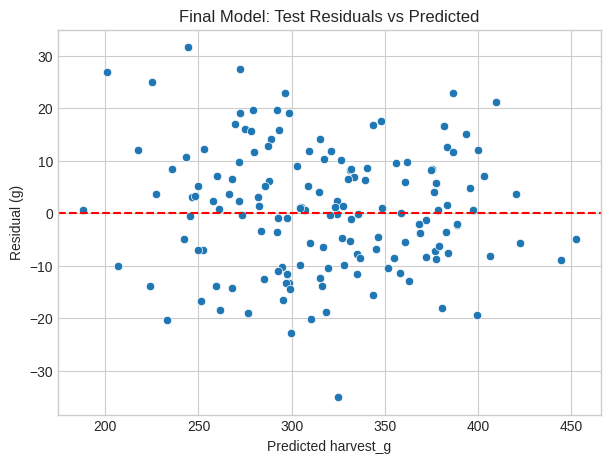

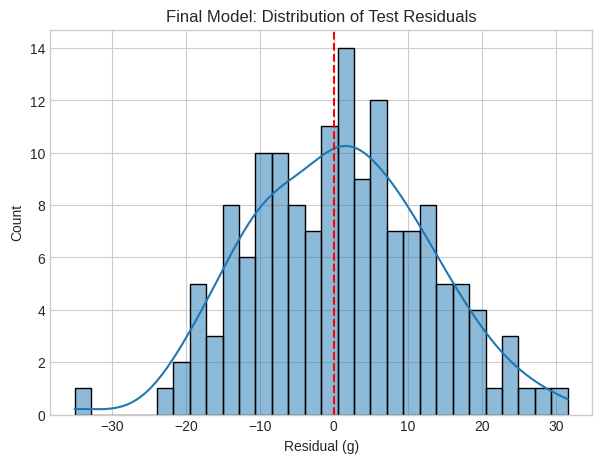

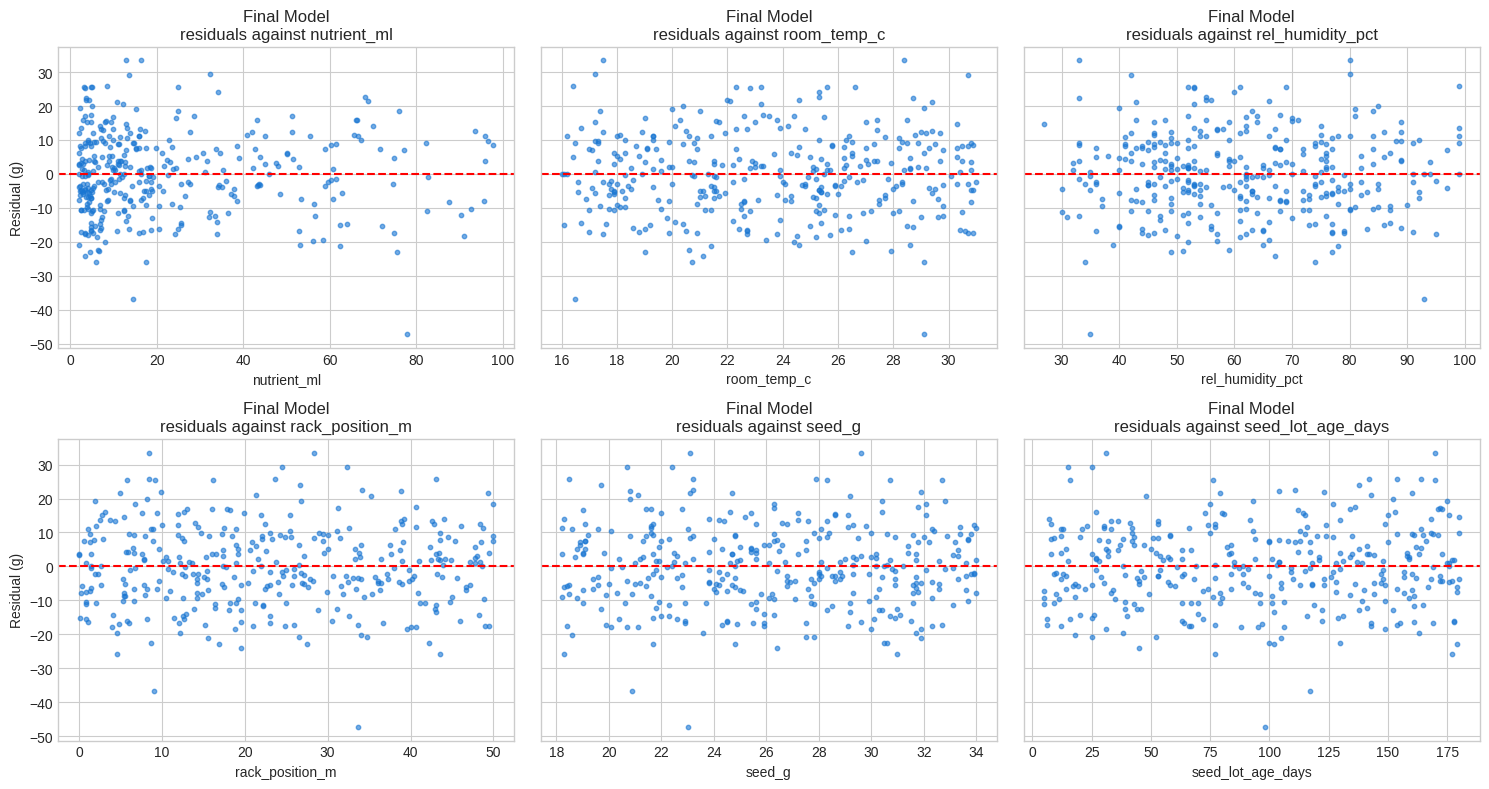

In [18]:
# Part 5.1 - Final equation, performance, and residual checks

# 1. Coefficient table
coef_table = pd.DataFrame({
    'Term': ['Intercept'] + final_cols,
    'Coefficient': [final_model.intercept_] + list(final_model.coef_)
})

print("Final Model Coefficients (Original Units)")
display(coef_table.round(3))


# 2. Performance comparison
naive_pred = model_1.predict(X_test[inputs])
final_pred = final_model.predict(X_test[final_cols])

performance_table = pd.DataFrame({
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, naive_pred)),
        np.sqrt(mean_squared_error(y_test, final_pred))
    ],
    'MAE': [
        mean_absolute_error(y_test, naive_pred),
        mean_absolute_error(y_test, final_pred)
    ],
    'R²': [
        r2_score(y_test, naive_pred),
        r2_score(y_test, final_pred)
    ]
}, index=['Naive Model 1', 'Final Model'])

print("\nTest Performance Comparison")
display(performance_table.round(3))


# 3. Final equation
b = pd.Series(final_model.coef_, index=final_cols)

print("\nFinal Equation:")
print(
    f"harvest_g = {final_model.intercept_:.3f}"
    f" + {b['room_temp_c']:.3f} * room_temp_c"
    f" {b['room_temp_c_sq']:+.3f} * room_temp_c^2"
    f" + {b['nutrient_log']:.3f} * ln(nutrient_ml)"
    f" + {b['seed_g']:.3f} * seed_g"
    f" {b['rack_position_m']:+.3f} * rack_position_m"
    f" + {b['rack_sin_8.600']:.3f} * sin(2π*rack_position_m/8.6)"
    f" {b['rack_cos_8.600']:+.3f} * cos(2π*rack_position_m/8.6)"
)


# 4. Test residuals vs predicted
test_residuals = y_test - final_pred

plt.figure(figsize=(7, 5))
sns.scatterplot(x=final_pred, y=test_residuals)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted harvest_g')
plt.ylabel('Residual (g)')
plt.title('Final Model: Test Residuals vs Predicted')
plt.show()


# 5. Histogram of test residuals
plt.figure(figsize=(7, 5))
sns.histplot(test_residuals, bins=30, kde=True)
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Residual (g)')
plt.title('Final Model: Distribution of Test Residuals')
plt.show()


# 6. Training residuals vs all original inputs
plot_residuals(
    final_model,
    X_train[final_cols],
    'Final Model'
)

*Your equation and your reading of the checks:*

The final model is:

**harvest_g = -620.375 + 69.344(room_temp_c) - 1.551(room_temp_c²) + 28.088 ln(nutrient_ml) + 5.323(seed_g) - 0.955(rack_position_m) + 14.744 sin(2π·rack_position_m/8.6) - 9.588 cos(2π·rack_position_m/8.6)**

On the test set, the final model has an RMSE of **11.789 g**, MAE of **9.498 g**, and R² of **0.952**. The simple Model 1 had an RMSE of **34.654 g**, MAE of **28.883 g**, and R² of **0.583**, so the final model predicts much better.

The test residuals versus predicted values are scattered around zero with no clear curve or trend. The histogram of test residuals is roughly centered around zero and is close to a bell shape, with a few larger errors.

For `nutrient_ml`, there is no strong remaining curved pattern. For `room_temp_c`, the earlier temperature curve is gone. For `rel_humidity_pct`, there is no clear pattern. For `rack_position_m`, the repeating wave is gone. For `seed_g`, there is no clear remaining pattern. For `seed_lot_age_days`, there is also no clear pattern.

Overall, the residual plots do not show a strong systematic pattern, and the test RMSE of about **11.8 g** is close to the expected **12 g** tray-to-tray variation.


### 5.2 Manager numbers, and one tray by hand **(2 pts — Technical Implementation) (1 pt — Verification Trail)**

- **Technical Implementation (2 pts):** translate each piece of your equation into numbers a
  manager can use, **computed in code from your coefficients** (not typed in): for a straight-line
  piece, grams per unit; for a parabola, where its peak or valley is and how many grams a setting
  away from it gains or loses; for a log piece, grams per doubling; for a wave, its height, how far
  apart its repeats are, and where its peaks and low points fall.
- **Verification Trail (1 pt):** predict **one test tray by hand**: type the equation out with its
  numbers and that tray's inputs, and show it matches `model.predict`.

In [19]:
import numpy as np
import pandas as pd

# Coefficients and Intercept from the final_model
final_intercept = final_model.intercept_
final_coefficients = pd.Series(final_model.coef_, index=final_cols)

print("--- Manager-Friendly Numbers ---")
print(f"Final Model Intercept: {final_intercept:.3f}")
print(f"Rack linear effect: {final_coefficients['rack_position_m']:.3f} grams per meter")

# 1. Straight-line terms (seed_g)
if 'seed_g' in final_coefficients.index:
    seed_g_coeff = final_coefficients['seed_g']
    print(f"Seed (seed_g): {seed_g_coeff:.3f} grams per gram of seed")


# 2. Temperature (room_temp_c and room_temp_c_sq)
if 'room_temp_c' in final_coefficients.index and 'room_temp_c_sq' in final_coefficients.index:
    b1_temp = final_coefficients['room_temp_c']
    b2_temp = final_coefficients['room_temp_c_sq']

    # Optimal temperature (peak of parabola) formula: -b1 / (2*b2)
    optimal_temp = -b1_temp / (2 * b2_temp)

    # Function to calculate temperature component's contribution
    def temp_contribution(temp, b1, b2):
        return b1 * temp + b2 * (temp**2)

    # Observed temperature range and Wes's preferred temp
    min_observed_temp = X_train['room_temp_c'].min()
    max_observed_temp = X_train['room_temp_c'].max()
    wes_temp = 26.0 # Wes's preferred temperature

    # Harvest effect at different temperatures
    peak_temp_harvest_effect = temp_contribution(optimal_temp, b1_temp, b2_temp)
    wes_temp_harvest_effect = temp_contribution(wes_temp, b1_temp, b2_temp)
    min_observed_temp_effect = temp_contribution(min_observed_temp, b1_temp, b2_temp)
    max_observed_temp_effect = temp_contribution(max_observed_temp, b1_temp, b2_temp)

    print(f"\nTemperature (room_temp_c):")
    print(f"  Optimal temperature for maximum harvest: {optimal_temp:.2f} °C")
    print(f"  Loss from optimal (relative to its component contribution):")
    print(f"    If running at Wes's 26.0 °C: {peak_temp_harvest_effect - wes_temp_harvest_effect:.3f} g")
    print(f"    If running at min observed {min_observed_temp:.1f} °C: {peak_temp_harvest_effect - min_observed_temp_effect:.3f} g")
    print(f"    If running at max observed {max_observed_temp:.1f} °C: {peak_temp_harvest_effect - max_observed_temp_effect:.3f} g")


# 3. Nutrient (nutrient_log)
if 'nutrient_log' in final_coefficients.index:
    nutrient_log_coeff = final_coefficients['nutrient_log']
    grams_per_doubling = nutrient_log_coeff * np.log(2)
    print(f"\nNutrient (nutrient_log):")
    print(f"  Each doubling of nutrient_ml is associated with: {grams_per_doubling:.3f} grams gained")

# 4. Rack Wave (rack_sin_8.600, rack_cos_8.600)
if 'rack_sin_8.600' in final_coefficients.index and 'rack_cos_8.600' in final_coefficients.index:
    sin_coeff = final_coefficients['rack_sin_8.600']
    cos_coeff = final_coefficients['rack_cos_8.600']
    period = 8.6 # Known period from analysis

    # Wave height (amplitude)
    wave_height = np.sqrt(sin_coeff**2 + cos_coeff**2)

    # Function to calculate wave component's contribution
    def wave_contribution(rack_pos, sin_c, cos_c, P):
        angle = 2 * np.pi * rack_pos / P
        return sin_c * np.sin(angle) + cos_c * np.cos(angle)

    # Observed rack position range
    min_rack = X_train['rack_position_m'].min()
    max_rack = X_train['rack_position_m'].max()

    # Calculate phase angle for peaks/troughs of A*sin(x) + B*cos(x) (where x = 2pi*rack_pos/P)
    # Peaks occur when x = atan2(A, B) + 2k*pi
    # Troughs occur when x = atan2(A, B) + pi + 2k*pi
    initial_peak_angle_rad = np.arctan2(sin_coeff, cos_coeff)
    initial_low_angle_rad = initial_peak_angle_rad + np.pi

    # Normalize angles to be within [0, 2*pi)
    initial_peak_angle_rad = (initial_peak_angle_rad % (2 * np.pi) + 2 * np.pi) % (2 * np.pi)
    initial_low_angle_rad = (initial_low_angle_rad % (2 * np.pi) + 2 * np.pi) % (2 * np.pi)

    # Convert initial angles back to rack_position_m
    initial_peak_rack_pos = initial_peak_angle_rad * period / (2 * np.pi)
    initial_low_rack_pos = initial_low_angle_rad * period / (2 * np.pi)

    peak_locations = []
    low_point_locations = []

    # Find all peak locations within the observed range by adding/subtracting the period
    current_pos = initial_peak_rack_pos
    while current_pos <= max_rack: # Forward search
        if current_pos >= min_rack:
            peak_locations.append(current_pos)
        current_pos += period
    current_pos = initial_peak_rack_pos - period
    while current_pos >= min_rack: # Backward search
        if current_pos <= max_rack: # Ensure it's not beyond max_rack due to subtracting period
            peak_locations.append(current_pos)
        current_pos -= period

    # Find all low point locations within the observed range
    current_pos = initial_low_rack_pos
    while current_pos <= max_rack: # Forward search
        if current_pos >= min_rack:
            low_point_locations.append(current_pos)
        current_pos += period
    current_pos = initial_low_rack_pos - period
    while current_pos >= min_rack: # Backward search
        if current_pos <= max_rack: # Ensure it's not beyond max_rack
            low_point_locations.append(current_pos)
        current_pos -= period

    peak_locations = sorted(list(set([round(loc, 2) for loc in peak_locations if min_rack <= loc <= max_rack])))
    low_point_locations = sorted(list(set([round(loc, 2) for loc in low_point_locations if min_rack <= loc <= max_rack])))

    print(f"\nRack Position Wave:")
    print(f"  Wave height (variation above/below average): {wave_height:.3f} grams")
    print(f"  Period (repeats every): {period:.1f} meters")
    print(f"  Approximate peak locations within observed range [{min_rack:.1f}m - {max_rack:.1f}m]:")
    print(f"    {', '.join([f'{loc:.2f} m' for loc in peak_locations])}")
    print(f"  Approximate low point locations within observed range [{min_rack:.1f}m - {max_rack:.1f}m]:")
    print(f"    {', '.join([f'{loc:.2f} m' for loc in low_point_locations])}")

    # Combined linear and wave effect for rack_position_m
    if 'rack_position_m' in final_coefficients.index:
        linear_coeff_rack = final_coefficients['rack_position_m']

        def combined_rack_effect(rack_pos, linear_c, sin_c, cos_c, P):
            linear_part = linear_c * rack_pos
            wave_part = wave_contribution(rack_pos, sin_c, cos_c, P)
            return linear_part + wave_part

        # Evaluate over a fine range to find overall highest/lowest points
        rack_positions_fine_overall = np.linspace(min_rack, max_rack, 500)
        combined_values = combined_rack_effect(
            rack_positions_fine_overall,
            linear_coeff_rack,
            sin_coeff,
            cos_coeff,
            period
        )

        overall_max_val = np.max(combined_values)
        overall_min_val = np.min(combined_values)
        overall_max_pos = rack_positions_fine_overall[np.argmax(combined_values)]
        overall_min_pos = rack_positions_fine_overall[np.argmin(combined_values)]

        print(f"  \nCombined Rack Position Effect (linear + wave) within observed range:")
        print(f"    Highest combined effect on harvest ({overall_max_val:.2f} g) at: {overall_max_pos:.2f} m")
        print(f"    Lowest combined effect on harvest ({overall_min_val:.2f} g) at: {overall_min_pos:.2f} m")


--- Manager-Friendly Numbers ---
Final Model Intercept: -620.375
Rack linear effect: -0.955 grams per meter
Seed (seed_g): 5.323 grams per gram of seed

Temperature (room_temp_c):
  Optimal temperature for maximum harvest: 22.36 °C
  Loss from optimal (relative to its component contribution):
    If running at Wes's 26.0 °C: 20.564 g
    If running at min observed 16.0 °C: 62.696 g
    If running at max observed 31.0 °C: 115.803 g

Nutrient (nutrient_log):
  Each doubling of nutrient_ml is associated with: 19.469 grams gained

Rack Position Wave:
  Wave height (variation above/below average): 17.587 grams
  Period (repeats every): 8.6 meters
  Approximate peak locations within observed range [0.0m - 50.0m]:
    2.94 m, 11.54 m, 20.14 m, 28.74 m, 37.34 m, 45.94 m
  Approximate low point locations within observed range [0.0m - 50.0m]:
    7.24 m, 15.84 m, 24.44 m, 33.04 m, 41.64 m
  
Combined Rack Position Effect (linear + wave) within observed range:
    Highest combined effect on harve

In [20]:
# Pick one test tray
tray_index = X_test.index[0]
tray_id = df.loc[tray_index, 'tray_id']

# Raw inputs for the tray
nutrient_ml = X_test.loc[tray_index, 'nutrient_ml']
room_temp_c = X_test.loc[tray_index, 'room_temp_c']
seed_g = X_test.loc[tray_index, 'seed_g']
rack_position_m = X_test.loc[tray_index, 'rack_position_m']

# Manually create transformed features
room_temp_c_sq = room_temp_c ** 2
nutrient_log = np.log(nutrient_ml)
rack_sin_8_600 = np.sin(2 * np.pi * rack_position_m / 8.6)
rack_cos_8_600 = np.cos(2 * np.pi * rack_position_m / 8.6)

print(f"--- Inputs for Tray ID: {tray_id} ---")
print(f"nutrient_ml: {nutrient_ml:.3f}")
print(f"room_temp_c: {room_temp_c:.3f}")
print(f"seed_g: {seed_g:.3f}")
print(f"rack_position_m: {rack_position_m:.3f}")

print("\n--- Transformed values ---")
print(f"room_temp_c^2: {room_temp_c_sq:.3f}")
print(f"ln(nutrient_ml): {nutrient_log:.3f}")
print(f"sin(2π*rack_position_m/8.6): {rack_sin_8_600:.3f}")
print(f"cos(2π*rack_position_m/8.6): {rack_cos_8_600:.3f}")

# Coefficients
final_intercept = final_model.intercept_
final_coefficients = pd.Series(final_model.coef_, index=final_cols)

b_temp = final_coefficients['room_temp_c']
b_temp_sq = final_coefficients['room_temp_c_sq']
b_nutrient = final_coefficients['nutrient_log']
b_seed = final_coefficients['seed_g']
b_rack = final_coefficients['rack_position_m']
b_sin = final_coefficients['rack_sin_8.600']
b_cos = final_coefficients['rack_cos_8.600']

# Calculate each part
term_temp = b_temp * room_temp_c
term_temp_sq = b_temp_sq * room_temp_c_sq
term_nutrient = b_nutrient * nutrient_log
term_seed = b_seed * seed_g
term_rack = b_rack * rack_position_m
term_sin = b_sin * rack_sin_8_600
term_cos = b_cos * rack_cos_8_600

print("\n--- Equation with this tray's values ---")
print(
    f"harvest_g = {final_intercept:.3f}"
    f" + ({b_temp:.3f} × {room_temp_c:.3f})"
    f" + ({b_temp_sq:.3f} × {room_temp_c_sq:.3f})"
    f" + ({b_nutrient:.3f} × {nutrient_log:.3f})"
    f" + ({b_seed:.3f} × {seed_g:.3f})"
    f" + ({b_rack:.3f} × {rack_position_m:.3f})"
    f" + ({b_sin:.3f} × {rack_sin_8_600:.3f})"
    f" + ({b_cos:.3f} × {rack_cos_8_600:.3f})"
)

print("\n--- Step-by-step calculation ---")
print(f"Intercept = {final_intercept:.3f}")
print(f"Temperature = {term_temp:.3f}")
print(f"Temperature squared = {term_temp_sq:.3f}")
print(f"Nutrient log = {term_nutrient:.3f}")
print(f"Seed = {term_seed:.3f}")
print(f"Rack linear = {term_rack:.3f}")
print(f"Rack sine = {term_sin:.3f}")
print(f"Rack cosine = {term_cos:.3f}")

# Manual prediction
manual_prediction = (
    final_intercept
    + term_temp
    + term_temp_sq
    + term_nutrient
    + term_seed
    + term_rack
    + term_sin
    + term_cos
)

# Model prediction for the same tray
single_tray = X_test.loc[[tray_index], final_cols]
model_prediction = final_model.predict(single_tray)[0]

print(f"\nManual prediction: {manual_prediction:.3f} g")
print(f"Model prediction: {model_prediction:.3f} g")
print(f"Match: {np.isclose(manual_prediction, model_prediction)}")

--- Inputs for Tray ID: PR-0362 ---
nutrient_ml: 7.500
room_temp_c: 23.300
seed_g: 24.000
rack_position_m: 31.900

--- Transformed values ---
room_temp_c^2: 542.890
ln(nutrient_ml): 2.015
sin(2π*rack_position_m/8.6): -0.967
cos(2π*rack_position_m/8.6): -0.253

--- Equation with this tray's values ---
harvest_g = -620.375 + (69.344 × 23.300) + (-1.551 × 542.890) + (28.088 × 2.015) + (5.323 × 24.000) + (-0.955 × 31.900) + (14.744 × -0.967) + (-9.588 × -0.253)

--- Step-by-step calculation ---
Intercept = -620.375
Temperature = 1615.712
Temperature squared = -841.876
Nutrient log = 56.595
Seed = 127.743
Rack linear = -30.475
Rack sine = -14.265
Rack cosine = 2.425

Manual prediction: 295.484 g
Model prediction: 295.484 g
Match: True


*Your manager numbers:*

The final model gives several numbers managers can use.

* **Seed:** Each extra 1 g of seed is associated with about **5.323 g more harvest**.
* **Temperature:** The model predicts the best temperature is about **22.36°C**. Running at Wes’s 26°C is about **20.56 g lower per tray** than the estimated peak.
* **Nutrient:** Each doubling of the nutrient dose is associated with about **19.47 g more harvest**.
* **Rack position:** The straight-line rack effect is about **-0.955 g per meter**.
* **Rack wave:** The repeating rack effect has a height of about **17.59 g** above or below its middle and repeats every **8.6 m**.
* The wave peaks occur around **2.94, 11.54, 20.14, 28.74, 37.34, and 45.94 m**.
* The low points occur around **7.24, 15.84, 24.44, 33.04, and 41.64 m**.

For the manual check, I used tray **PR-0362**. My hand calculation predicted **295.484 g**, and `final_model.predict()` also gave **295.484 g**, so the calculations match.


### 5.3 Imani's answers **(8 pts — Understanding)**

Answer in grams **and** dollars (\$0.07 per gram, 1,500 trays a week), and word every effect as
"*is associated with … holding the other inputs constant*":

1. **Temperature:** the setting your equation supports, and what running at Wes's 26 °C instead is
   associated with, per tray and per week.
2. **Nutrient:** what raising the dose from 25 to 50 mL, and from 50 to 100 mL, is associated with,
   against what the concentrate costs at \$0.04 per mL. What does that mean for purchasing's full
   dose?
3. **Any other piece of your equation:** what it is associated with, per tray. For a wave, where
   its peaks and low points fall; and if the same column also has a straight-line piece, where along
   that column the line and the wave added together are highest and lowest.
4. **Seed:** what an extra gram of seed is associated with.

*Your answer here:*

**Temperature**: The model supports about 22.36°C. Running at Wes's 26°C is associated with about 20.56 g less harvest per tray, holding the other inputs constant. That is about $1.44 less per tray or about $2,159 less per week across 1,500 trays.

**Nutrient**: Raising nutrient from 25 to 50 mL is associated with about 19.47 g more harvest per tray, holding the other inputs constant. That harvest is worth about $1.36 per tray or $2,044 per week. The extra nutrient costs $1.00 per tray or $1,500 per week, leaving about $0.36 per tray or $544 per week after nutrient cost. Raising nutrient from 50 to 100 mL is associated with the same 19.47 g increase, holding the other inputs constant, worth about $1.36 per tray or $2,044 per week. However, the extra 50 mL costs $2.00 per tray or $3,000 per week, so the change loses about $0.64 per tray or $956 per week after nutrient cost. This does not support purchasing's full 100 mL dose.

**Rack position:** Moving 1 meter farther down the rack is associated with about 0.955 g less harvest, or about $0.07 less per tray, holding the other inputs constant. The repeating wave is associated with variation of about 17.59 g, or $1.23 per tray, above or below its middle, holding the other inputs constant. Peaks occur around 2.94, 11.54, 20.14, 28.74, 37.34, and 45.94 m, and low points around 7.24, 15.84, 24.44, 33.04, and 41.64 m. When the line and wave are combined, the rack effect is highest around 2.81 m and lowest around 50 m. The difference is associated with about 79.91 g, or $5.59 per tray, holding the other inputs constant.

**Seed:** One extra gram of seed is associated with about 5.323 g more harvest per tray, holding the other inputs constant, worth about $0.37 per tray or about $559 per week if all 1,500 trays receive one extra gram.


### 5.4 Humidity and seed-lot age **(4 pts — Understanding)**

Alicia's humidity finding and Wes's seed-lot rule. For each: what did your naive step-1 model say,
what does your final model say, and what evidence from your correlation check and drop test supports your
conclusion? Explain any difference between the two models' answers. What should Imani do about the
\$38,000 dehumidifier request, and does Wes's rule survive?

*Your answer here:*

Humidity: In the naive model, humidity had a coefficient of about -0.638 g per percentage point, which made it look like higher humidity reduced harvest. In the final model, humidity is removed. The correlation check showed humidity and temperature were strongly correlated at -0.913, so humidity could borrow some of temperature's effect when the temperature curve was not modeled correctly. Dropping humidity from Model 4 changed test RMSE from 11.790 to 11.783, so it did not improve prediction. Imani should not approve the $38,000 dehumidifier based on this trial's yield evidence alone.

Seed-lot age: The naive model gave seed-lot age a very small positive coefficient of about +0.021 g per day, which already did not support Wes's claim that older lots reduce harvest. In the final model, seed-lot age is removed. It was only weakly correlated with the other inputs, and dropping it changed test RMSE only from 11.790 to 11.815, which is well below the 1% threshold. Wes's seed-lot rule is therefore not supported by this trial.


### 5.5 Your table in this week's terms **(4 pts — Understanding)**

Which rows of your growing table **underfit**, and how can you tell? Which extra columns from Part 4
would only have fitted noise? **Why can test RMSE not go much below about 12 g**, however good the
model? And what would a test RMSE of 3 g make you suspect?

*Your answer here:*

The clearly underfit models were the early models and the wrong wave models because their test RMSE was still well above the expected 12 g noise level and their residual plots still showed patterns. Model 1 had test RMSE 34.654, the temperature model 21.673, the nutrient model 18.112, and wrong coarse wave periods such as 6.88 and 10.32 m still had test RMSE around 18 g.

The extra room_temp_c_cube and seed_g_sq columns mainly fitted noise. They slightly lowered training RMSE but made test RMSE slightly worse.

Test RMSE cannot go much below about 12 g because the data contain about 12 g of random tray-to-tray variation that the inputs cannot predict. If I saw a test RMSE of 3 g, I would suspect data leakage, overfitting to the test set, an incorrect split, or another coding error.

---

## Part 6: Critical analysis

### 6.1 Spot the errors **(8 pts — Critical Analysis, 2 pts per error)**

Gemini was asked for *"a complete model with every transformation, tuned for the best accuracy"*
and returned the cell below. It has **four** errors that this week's material lets you catch. One
stops it running; the other three would not, and they are the more dangerous kind.

Run it (it is meant to fail). Then fill in the table and, in the cell after it, write and run your
corrected version.

In [21]:
# AI-GENERATED CODE -- DO NOT TRUST IT
# The prompt: "a complete model with every transformation, tuned for the best accuracy"
# NOTE: this cell is *supposed* to raise an error. That is one of its four errors.
features = ['nutrient_ml', 'room_temp_c', 'rel_humidity_pct', 'rack_position_m', 'seed_g', 'seed_lot_age_days']
X_all = np.log(df[features])                   # log everything: business data is skewed
for column in features:
    X_all[column + '_sq'] = df[column] ** 2    # and square everything, to catch any curve

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_all), columns=X_all.columns, index=df.index)

X_tr, X_te, y_tr, y_te = train_test_split(X_scaled, df['harvest_g'], test_size=0.3, random_state=42)

best_rmse, best_wave = None, None
for column in features:                        # try a wave on every input...
    for period in np.arange(2, 30, 0.25):      # ...at every period, and keep the best
        wave_tr = np.sin(df.loc[X_tr.index, column] / period)
        wave_te = np.sin(df.loc[X_te.index, column] / period)
        model = LinearRegression().fit(X_tr.assign(wave=wave_tr), y_tr)
        rmse = np.sqrt(mean_squared_error(y_te, model.predict(X_te.assign(wave=wave_te))))
        if best_rmse is None or rmse < best_rmse:
            best_rmse, best_wave = rmse, (column, period)

print(f"Best wave: {best_wave[0]}, period {best_wave[1]}")
print(f"Expected error on new trays: {best_rmse:.1f} g")

/usr/local/lib/python3.13/dist-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)


ValueError: Input X contains infinity or a value too large for dtype('float64').

| # | The line(s)                                                                    | What is wrong                                                                                                  | What it would do to Pelican Row’s numbers or decisions                                                | Your fix                                                                                                                         |
| - | ------------------------------------------------------------------------------ | -------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------- |
| 1 | `X_all = np.log(df[features])`                                                 | It takes the log of every input. `rack_position_m` contains 0, so `log(0)` becomes invalid and the code fails. | The model cannot run, so no usable result is produced.                                                | Only log a variable when the residual pattern supports it. Here, use `np.log(nutrient_ml)` only.                                 |
| 2 | `scaler.fit_transform(X_all)` before `train_test_split()`                      | The scaler learns from the full dataset, including the test rows. This is data leakage.                        | Test performance can look better than it really is, which could make managers trust a model too much. | Split first. If scaling is needed, fit the scaler only on the training data and transform the test data with that fitted scaler. |
| 3 | `np.sin(df[...] / period)` and only one wave column                            | The wave formula is wrong. It is missing `2π`, and a flexible wave needs both sine and cosine.                 | It could choose the wrong rack pattern and give wrong peak/low locations.                             | Use both `sin(2πx/P)` and `cos(2πx/P)`.                                                                                          |
| 4 | Trying every period from 2 to 30 by 0.25 and choosing the lowest **test** RMSE | It uses the test set hundreds of times to tune the model. The test set is no longer truly unseen.              | The reported test RMSE can look too good because the model was indirectly fitted to the test set.     | Estimate the period from training residuals, then test only a few coarse and fine candidates and stop.                           |


In [ ]:
# Corrected version

# Split first
X = df[inputs]
y = df['harvest_g']

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_tr = X_tr.copy()
X_te = X_te.copy()

# Add only transformations supported by the earlier residual analysis
X_tr['room_temp_c_sq'] = X_tr['room_temp_c'] ** 2
X_te['room_temp_c_sq'] = X_te['room_temp_c'] ** 2

X_tr['nutrient_log'] = np.log(X_tr['nutrient_ml'])
X_te['nutrient_log'] = np.log(X_te['nutrient_ml'])

# Rack wave using the supported period
P = 8.6

X_tr['rack_sin'] = np.sin(2 * np.pi * X_tr['rack_position_m'] / P)
X_te['rack_sin'] = np.sin(2 * np.pi * X_te['rack_position_m'] / P)

X_tr['rack_cos'] = np.cos(2 * np.pi * X_tr['rack_position_m'] / P)
X_te['rack_cos'] = np.cos(2 * np.pi * X_te['rack_position_m'] / P)

corrected_cols = [
    'room_temp_c',
    'room_temp_c_sq',
    'nutrient_log',
    'seed_g',
    'rack_position_m',
    'rack_sin',
    'rack_cos'
]

corrected_model = LinearRegression().fit(
    X_tr[corrected_cols],
    y_tr
)

train_pred = corrected_model.predict(X_tr[corrected_cols])
test_pred = corrected_model.predict(X_te[corrected_cols])

train_rmse = np.sqrt(mean_squared_error(y_tr, train_pred))
test_rmse = np.sqrt(mean_squared_error(y_te, test_pred))
test_r2 = r2_score(y_te, test_pred)

print(f"Training RMSE: {train_rmse:.3f}")
print(f"Test RMSE: {test_rmse:.3f}")
print(f"Test R²: {test_r2:.3f}")

### 6.2 Limits **(4 pts — Critical Analysis)**

1. **Ranges:** what ranges did the trial cover, and where is your data thin?
2. **Association, not cause:** for each piece you found, could something other than the input
   itself explain the pattern? For any repeating pattern, what physical thing might produce it, and
   what would you go and inspect?
3. **"It doesn't matter":** if your final model leaves an input out, a manager may say "so that
   setting doesn't matter; we can let it drift anywhere." What would the trial have needed to vary
   for that conclusion to hold?
4. **The test set and the trial:** how many times did you use the test set to make a choice, and
   what does that do to your final test RMSE? What can one simulated trial not tell Imani about next
   season?

*Your answer here:*

**1. Ranges:** The trial covered nutrient from **2.0–97.8 mL**, temperature from **16–31°C**, humidity from **24–99%**, rack position from **0–50 m**, seed from **18.1–34.0 g**, and seed-lot age from **5–180 days**. The nutrient data are thinner at high doses because most trays received lower amounts.

**2. Association, not cause:** These results show associations, not guaranteed cause. Temperature, nutrient, and seed were deliberately varied, which gives stronger evidence, but other differences such as room conditions, watering, handling, batch, or seed quality could still explain part of the patterns if the settings were not independently randomized. The rack trend and repeating wave could come from physical conditions such as lights, fans, vents, or irrigation equipment. I would inspect those systems along the rack, especially near the estimated peaks and low points.

**3. “It doesn't matter”:** Leaving humidity or seed-lot age out does not mean they can vary anywhere without consequences. To support that conclusion, the trial would need to deliberately and independently vary those inputs across their full operating ranges while controlling the other settings.

**4. Test set and trial:** I used the test set about 29 times while comparing transformations, the first incorrect rack-wave search, the corrected wave search, extra features, and drop tests. Because I used the test set repeatedly to make choices, the final 11.789 g test RMSE may be somewhat optimistic. One simulated trial also cannot prove that the same equation will work next season under different equipment, seed lots, or operating conditions.

### 6.3 The vendor's one-shot formula **(3 pts — Critical Analysis)**

The sensor vendor pasted the CSV into an AI assistant and, in one shot, got back a formula with a
test R² close to 0.9, which it called "excellent". Suppose that formula is the **first model you
kept** in your growing table whose test R² reached 0.88. Put it next to your final model: which
pieces does it lack, and what would the farm get wrong if its planning system used it? Give at least
one consequence in dollars. Why is a test R² near 0.9 not evidence that the rule has been found?

*Your answer here:*

The vendor's formula would match my **Model 3**, the first kept model with test R² above 0.88. It had **R² = 0.886** and **test RMSE = 18.112 g**, compared with **R² = 0.952** and **RMSE = 11.789 g** for my final model.

The main missing piece is the **8.6 m rack-position wave**. The earlier model also keeps variables that the final drop tests showed were unnecessary, such as humidity, seed-lot age, and raw nutrient.

Without the rack wave, the farm would miss important high and low positions along the rack. The wave changes harvest by about **35.17 g from a peak to a low point**, worth about **$2.46 per tray** or about **$3,693 across 1,500 trays** at that scale.

A test R² near 0.9 does not prove that the full rule was found. Model 3 still had a clear repeating pattern in its residuals and an RMSE well above the expected **12 g** tray-to-tray variation.


---

## Part 7: Reflection and AI Usage Report

Answer these in **your own words**. AI-generated reflections receive zero credit —
they are easy to spot, because they are fluent and say nothing specific.

> **Why this section exists.** You are required to use AI in this course, and using
> it responsibly is a professional skill in its own right — one that has to be
> practised, not assumed. That skill starts here: stating plainly what you asked,
> what came back, how you checked it, and what you changed when the check failed.
> An engineer who cannot account for where their code came from cannot be trusted
> with it, and neither can an analyst. Recounting your own process is how you learn
> to notice it.

### 7.1 Prompt evolution log

```text
Attempt 1: I asked Gemini to find the repeating rack period.
   Result: It gave peak locations [2, 6, 10, 14, ... 50] and estimated a 4.0 m period.
   How I checked it: I looked back at the zoomed residual plot and the points it called peaks did not match the real positive peaks. After fitting the suggested wave, the rack pattern was still visible.
   Problem: The peak readings were wrong.

Attempt 2: I corrected the visible peaks to about [3, 12, 20, 29, 38, 46].
   Result: The estimated period became (46 - 3) / (6 - 1) = 8.6 m.
   How I checked it: The 8.6 m sine + cosine model lowered test RMSE from 18.112 to 11.790 and removed the repeating rack pattern.
   Problem: I still wanted to check whether a nearby period could perform better.

Attempt 3: I checked nearby periods 8.256 and 8.944.
   Result: 8.6 m still had the lowest test RMSE, so I kept it.
   How I checked it: I compared the test RMSE for all three periods and checked the final residual plot.
```

### 7.2 Where the AI struggled

One place Gemini struggled was the rack-position wave. It first read the peaks as every 4 meters and gave me a period of 4.0 m. The code ran, so at first it looked fine, but the residual plot still had a clear wave and the RMSE was still around 18 g. I had to know how to read the peaks from the residual plot and check whether the pattern actually disappeared. After correcting the peaks, I got a period of 8.6 m and the RMSE dropped to about 11.79 g.

### 7.3 What was harder or easier than expected

The coding was easier than I expected because Gemini could help generate a lot of the Python. The harder part was deciding whether the result actually made sense. I had to keep checking the residual plots, RMSE, and whether adding a feature really improved the model. I also learned that a high R² does not automatically mean the model is finished.

### 7.4 Confidence self-assessment

| Topic                      | 1–5 | What would move this up one point?                                              |
| -------------------------- | --: | ------------------------------------------------------------------------------- |
| Linear regression          |   4 | More practice explaining coefficients without checking my notes.                |
| Residual plots             |   4 | More practice finding smaller or less obvious patterns.                         |
| Transformations            |   3 | More practice knowing when to use log, square, or wave terms by myself.         |
| Business interpretation    |   4 | More practice turning model results into dollars and business decisions faster. |
| Checking AI-generated code |   4 | More practice catching mistakes before I run the code.                          |

### 7.5 AI Usage Report

I used **Gemini in Google Colab** throughout this assignment. I mainly used it to help generate Python code for data checking, regression models, transformations, residual plots, candidate comparisons, drop tests, and the final business calculations.

I did not accept every result as-is. I ran the code and checked the RMSE, R², and residual plots after each step. I accepted results when the numbers and plots supported them, such as the temperature-square and nutrient-log transformations.

The main result I corrected was the rack-position wave. Gemini first estimated the period as about **4.0 m** and later selected **3.84 m**, but the test RMSE stayed around 18 g and the rack pattern was still visible. I went back to the residual plot, corrected the peak locations, and got a period of **8.6 m**.

I also checked the final model using drop tests before removing humidity, seed-lot age, and raw nutrient. Finally, I calculated one test tray by hand and confirmed that my result matched `final_model.predict()`.

I attached the full Gemini conversation export as a separate file.

### 7.6 A one-shot AI test **(2 pts — AI Usage Report)**

Give Gemini **only** the data dictionary above and the output of `df.head()`, and ask it for the
formula for `harvest_g`. Fit **exactly** the formula it gives you on your split with `score`, and
report its test RMSE. Which of your pieces did it get right, which did it get wrong or miss, and what
in your discovery trail could it not have known from what you gave it?

In [ ]:
columns_one_shot = [
    'nutrient_ml',
    'room_temp_c',
    'rel_humidity_pct',
    'rack_position_m',
    'seed_g',
    'seed_lot_age_days'
]

# Create temporary DataFrames for the one-shot model using only original inputs
X_tr_one_shot = X_train[columns_one_shot]
X_te_one_shot = X_test[columns_one_shot]

# Fit the one-shot linear regression model
one_shot_model = LinearRegression().fit(X_tr_one_shot, y_train)

# Score the one-shot model
score_df = score(
    'One-shot AI model (linear, all original inputs)',
    one_shot_model,
    X_tr_one_shot,
    X_te_one_shot
)

print(score_df.loc[['One-shot AI model (linear, all original inputs)']].round(3))

*Your answer here:*

I gave Gemini only the data dictionary and the output of `df.head()`. It suggested a simple linear regression using all six original inputs with no transformations.

I fitted exactly that formula using the same train/test split. The model had a **test RMSE of 34.654 g** and **test R² of 0.583**.

The one-shot model got one basic idea right: the original inputs can be used as predictors. However, it missed the important shapes I found later, including the **temperature curve**, **log nutrient effect**, and **8.6 m rack-position wave**. It also kept humidity and seed-lot age even though my later drop tests showed they were not needed.

Gemini could not have known these shapes from only the data dictionary and five rows. The important relationships only became clear after using the full training data, checking residual plots, testing transformations, and comparing model performance.


### 7.7 One AI suggestion you tested and rejected **(1 pt — AI Usage Report)**

Quote at least one suggestion an AI assistant made during this assignment that you **tested and
rejected**, and point to the table row or plot that rejected it.

*Your answer here:*

One Gemini suggestion I tested and rejected was:

`peak_locations = [2, 6, 10, 14, 18, 22, 26, 30, 34, 38, 42, 46, 50]`

This suggested a rack period of about **4.0 m**. I tested it, but the model still had a test RMSE around **18.05 g**, and the rack-position residual plot still showed a clear repeating wave.

I went back to the plot and used peaks around **3, 12, 20, 29, 38, and 46 m**, which gave a period of **8.6 m**. The **8.6 m** model reduced test RMSE to **11.790 g** and removed the repeating pattern, so I rejected the original 4.0 m suggestion.


---

## Video walkthrough

**3–5 minutes, hard stop at five.** Record it in **your own running notebook**, and show:

1. **one residual plot** that led you to add a column, and what you saw in it;
2. **your peak reading** and your **period-candidate table**;
3. **one sentence on Alicia's humidity claim** and what your evidence says about it;
4. **your final equation**, and **one dollar figure** for Imani.

Talk the way you would explain it to a colleague; do not read a script. Graders compare the video with
the plots in your notebook.

---

## Before you submit

- [ ] **Kernel -> Restart & Run All**, top to bottom. Save the file *after* it has
      run, so your outputs are in what you upload.
- [ ] **One exception:** the AI-generated cell in the *Spot the error* section may
      stop the run -- that cell is **meant** to fail, and that is the point of the
      exercise. Run your corrected version by hand afterwards so its output is
      saved, then save the notebook. Nothing else should raise.
- [ ] Every *your answer here* prompt is filled in, in **your own words**.
- [ ] Your **AI Usage Report** is complete -- the prompting, the results, the
      checking, the re-prompting, and one thing you rejected -- **plus the full
      conversation export attached as a separate file.** The written account alone
      does not satisfy it.
- [ ] File named **`LastName_FirstName_Week04.ipynb`**.
- [ ] Video recorded and submitted -- **file upload on the Canvas assignment, or a
      publicly accessible link in the Canvas submission comment**. Not in this
      notebook. Test the link signed out: no video, or a link we cannot open, is
      **-15 points**.